# Makine Öğrenmesi Tabanlı Saldırı Tespit Sistemlerinin Adversarial Evasion Saldırılarına Karşı Dayanıklılığı

*Evaluating the Robustness of Machine Learning-Based Intrusion Detection Systems Against Adversarial Evasion Attacks*

**Veri seti:** CIC-IDS2017 (MachineLearningCVE, 8 günlük akış kaydı)
**Modeller:** Random Forest, XGBoost, MLP

**Araştırma sorusu.** Adversarial perturbation uygulamaları, makine öğrenmesi tabanlı ağ saldırısı tespit modellerinin performansını ne ölçüde düşürmektedir ve hangi model bu değişikliklere karşı daha dayanıklıdır?

**Hipotez H1.** Adversarial perturbation seviyesi arttıkça saldırı tespit modellerinin saldırı sınıfına ilişkin Recall ve F1-score değerleri düşmektedir.

| Bölüm | İçerik |
|---|---|
| 1–3 | Veri yükleme, temizleme, sınıf dengesizliği |
| 4 | Modeller ve değerlendirme protokolü |
| 5 | Veri sızıntısı analizi |
| 6 | Özellik grupları, tehdit modeli ve pertürbasyon kısıtları |
| 7 | Deney A (baseline), Deney B (pertürbasyon duyarlılığı), Deney C (dayanıklılık karşılaştırması) |
| 8 | Deney D (özellik önemi ve grup ablation) |
| 9–10 | Sonuç özeti, tartışma ve sınırlılıklar |

In [1]:
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from IPython.display import display
from scipy.stats import spearmanr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
)
from xgboost import XGBClassifier

In [2]:
# Dosya yolları
DATA_DIR = Path("../data/raw/MachineLearningCVE")
RESULTS_DIR = Path("../results")
GRAPHS_DIR = RESULTS_DIR / "graphs"
METRICS_DIR = RESULTS_DIR / "metrics"
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Deney ayarları
SEEDS = [42, 100, 2024]                       
TEST_SIZE = 0.20
EPSILONS = [0.0, 0.05, 0.10, 0.25, 0.50, 1.00]  # pertürbasyon seviyesi: özellik başına izin verilen en büyük göreli artış
EPS_REF = 0.50                                  # karşılaştırma tabloları, confusion matrix ve ablation için referans seviye
ADAPTIVE_GRID = 4                               # uyarlamalı saldırganın her özellik grubu için denediği katsayı sayısı
ABLATION_TRAIN_SIZE = 400_000                   # ablation'da her varyant için kullanılan eğitim örneği sayısı
DECISION_THRESHOLD = 0.5

MODEL_NAMES = ["Random Forest", "XGBoost", "MLP"]
METRIC_COLS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
ATTACKERS = ["Random", "Adaptive"]
SCENARIO_GROUPS = ["Size", "Time", "Size+Time"]

assert EPS_REF in EPSILONS

In [3]:
# Grafik ve tablo stili
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"

MODEL_COLORS = {"Random Forest": "#2a78d6", "XGBoost": "#eb6834", "MLP": "#1baf7a"}
SCENARIO_COLORS = {"Clean": AXIS, "Size": "#eda100", "Time": "#e87ba4", "Size+Time": "#008300"}
GROUP_COLORS = {"Size": "#eda100", "Time": "#e87ba4", "Rate": "#6250d6", "Count/Protocol": MUTED}
BLUE_SEQ = LinearSegmentedColormap.from_list(
    "blue_seq", ["#f2f7fe", "#b7d3f6", "#5598e7", "#1c5cab", "#0d366b"]
)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 8,
    "axes.labelsize": 10, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 6,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

TABLE_STYLES = [
    {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: 600; "
                                     "font-size: 13px; color: #0b0b0b; padding: 4px 0 8px 0;"},
    {"selector": "th", "props": "background: #f3f2ee; color: #0b0b0b; font-weight: 600; text-align: left; "
                                "padding: 6px 12px; border-bottom: 1px solid #c3c2b7;"},
    {"selector": "td", "props": "padding: 5px 12px; border-bottom: 1px solid #ecebe6; "
                                "font-variant-numeric: tabular-nums;"},
]


def save_fig(fig, name):
    fig.savefig(GRAPHS_DIR / f"{name}.png")
    plt.show()


def fig_title(fig, title, subtitle=None):
    # Başlık ve alt başlık, eksenlerin üstüne sabit (inç cinsinden) boşlukla yerleştirilir.
    h = fig.get_figheight()
    fig.text(0.01, 1 + 0.42 / h, title, ha="left", va="bottom", fontsize=12.5, fontweight="semibold")
    if subtitle:
        fig.text(0.01, 1 + 0.14 / h, subtitle, ha="left", va="bottom", fontsize=9.5, color=INK_2)


def top_legend(fig, handles, labels=None, **kwargs):
    h = fig.get_figheight()
    labels = labels if labels is not None else [hd.get_label() for hd in handles]
    fig.legend(handles, labels, loc="lower right", bbox_to_anchor=(0.995, 1 + 0.36 / h),
               ncol=kwargs.pop("ncol", len(handles)), **kwargs)


def show_table(df, title, filename=None, precision=4):
    # Tabloyu CSV olarak kaydeder ve notebook'ta biçimlendirilmiş hâlde gösterir.
    if filename:
        df.to_csv(METRICS_DIR / filename, index=False, encoding="utf-8-sig")
    styler = (df.style.set_caption(title).hide(axis="index")
              .set_table_styles(TABLE_STYLES).format(precision=precision, thousands=","))
    display(styler)


def format_pm(mean, std, digits=4):
    # Ortalama ve standart sapma tablolarını "ortalama ± std" metnine çevirir.
    out = pd.DataFrame(index=mean.index)
    for col in mean.columns:
        d = digits.get(col, 4) if isinstance(digits, dict) else digits
        out[col] = [f"{m:,.{d}f} ± {s:,.{d}f}" for m, s in zip(mean[col], std[col].fillna(0))]
    return out

## 1. Veri Setinin Yüklenmesi

CIC-IDS2017'nin 8 günlük CSV dosyası tek bir tabloda birleştirilir. Ham dosyalarda iki biçim sorunu düzeltilir:

- Sütun adlarının başında boşluk vardır (`" Label"`); adlar `strip()` ile temizlenir.
- Web saldırısı etiketlerindeki tire karakteri hatalı kodlanmıştır (`Web Attack � Brute Force`); `-` ile değiştirilir.

In [4]:
csv_files = sorted(DATA_DIR.glob("*.csv"))
frames = []
for path in csv_files:
    df = pd.read_csv(path, low_memory=False)
    df.columns = df.columns.str.strip()
    frames.append(df)
    print(f"{path.name:<62}{len(df):>12,} satır")

data = pd.concat(frames, ignore_index=True)
del frames

data["Label"] = (data["Label"].astype(str)
                 .str.replace("�", "-", regex=False)
                 .str.replace("\x96", "-", regex=False)
                 .str.strip())

# Ham veride tam sayı olan sütunlar (pertürbasyondan sonra yuvarlanacak)
INT_COLS_RAW = [c for c in data.columns if pd.api.types.is_integer_dtype(data[c])]

print(f"\nToplam: {data.shape[0]:,} satır, {data.shape[1]} sütun")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                   225,745 satır
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv               286,467 satır
Friday-WorkingHours-Morning.pcap_ISCX.csv                          191,033 satır
Monday-WorkingHours.pcap_ISCX.csv                                  529,918 satır
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv        288,602 satır
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv             170,366 satır
Tuesday-WorkingHours.pcap_ISCX.csv                                 445,909 satır
Wednesday-workingHours.pcap_ISCX.csv                               692,703 satır

Toplam: 2,830,743 satır, 79 sütun


## 2. Veri Temizleme

Temizlik adımları ve gerekçeleri:

1. **Sonsuz ve eksik değerler.** `Flow Bytes/s` ve `Flow Packets/s` sütunlarında süre 0 olduğunda sonsuz değer oluşur. Sonsuz değerler eksik değere çevrilir ve eksik değer içeren satırlar silinir.
2. **Fiziksel olarak geçersiz değerler.** Süre, paket boyutu ve hız gibi özellikler negatif olamaz; CICFlowMeter'ın ürettiği negatif değerli satırlar silinir. `Init_Win_bytes_*` sütunlarındaki `-1` "gözlenmedi" anlamına geldiği için bu kuraldan muaftır.
3. **Sabit sütunlar.** Tüm satırlarda aynı değeri alan sütunlar bilgi taşımaz ve silinir.
4. **Birebir aynı sütunlar.** Başka bir sütunun kopyası olan sütunlar (ör. `Fwd Header Length.1`) silinir.
5. **`Destination Port`.** Hedef port bir akış davranışı değil, bir tanımlayıcıdır. Saldırılar belirli portlara yoğunlaştığı için model saldırıyı değil portu öğrenebilir (bkz. Bölüm 5). Bu nedenle model özelliklerinden çıkarılır ve yalnızca sızıntı analizinde kullanılır.
6. **Etiket çakışması ve tekrar eden satırlar.** Özellikleri aynı olup hem "normal" hem "saldırı" etiketi taşıyan satırlar belirsiz olduğu için tamamen silinir. Ardından tekrar eden satırlar tekilleştirilir; böylece aynı akışın hem eğitim hem test kümesine düşmesi engellenir.

In [5]:
cleaning_log = []


def log_step(step, rows_before, cols_before, note):
    cleaning_log.append({
        "Step": step,
        "Rows removed": rows_before - len(data),
        "Columns removed": cols_before - data.shape[1],
        "Rows remaining": len(data),
        "Note": note,
    })


num_cols = data.columns.drop("Label")

# 1) Sonsuz ve eksik değerler
r, c = data.shape
n_inf = int(np.isinf(data[num_cols]).sum().sum())
data[num_cols] = data[num_cols].replace([np.inf, -np.inf], np.nan)
data = data.dropna()
log_step("Infinite / missing values", r, c, f"{n_inf:,} infinite values converted to missing")

# 2) Fiziksel olarak geçersiz (negatif) değerler
r, c = data.shape
nonneg_cols = [col for col in num_cols if not col.startswith("Init_Win_bytes")]
negative_counts = (data[nonneg_cols] < 0).sum()
negative_counts = negative_counts[negative_counts > 0].sort_values(ascending=False)
data = data[(data[nonneg_cols] >= 0).all(axis=1)]
log_step("Negative values", r, c, f"Negative values found in {len(negative_counts)} columns")

# 3) Sabit sütunlar
r, c = data.shape
constant_cols = [col for col in num_cols if data[col].nunique() <= 1]
data = data.drop(columns=constant_cols)
log_step("Constant columns", r, c, ", ".join(constant_cols))

# 4) Birebir aynı sütunlar (önce içerik özeti karşılaştırılır, sonra equals ile doğrulanır)
r, c = data.shape
seen, duplicate_cols = {}, []
for col in data.columns.drop("Label"):
    digest = hashlib.md5(pd.util.hash_pandas_object(data[col], index=False).values.tobytes()).hexdigest()
    if digest in seen and data[col].equals(data[seen[digest]]):
        duplicate_cols.append(col)
    else:
        seen.setdefault(digest, col)
data = data.drop(columns=duplicate_cols)
log_step("Duplicate columns", r, c, ", ".join(duplicate_cols))

# 5) Destination Port: model özelliklerinden çıkarılır (sızıntı analizi için tabloda kalır)
FEATURES = [col for col in data.columns if col not in ("Label", "Destination Port")]
log_step("Destination Port", len(data), data.shape[1] + 1, "Identifier feature; used only in the leakage analysis")

# 6) Etiket çakışması ve tekrar eden satırlar
data["Target"] = (data["Label"] != "BENIGN").astype("int8")
r, c = data.shape
row_hash = pd.util.hash_pandas_object(data[FEATURES], index=False)
n_targets = data["Target"].groupby(row_hash.values).transform("nunique")
data = data[(n_targets == 1).values]
log_step("Label conflicts", r, c, "Identical features labelled both benign and attack")

r, c = data.shape
row_hash = pd.util.hash_pandas_object(data[FEATURES], index=False)
data = data[~row_hash.duplicated().values].reset_index(drop=True)
log_step("Duplicate rows", r, c, "Rows with identical features deduplicated")

X = data[FEATURES].astype("float64")
y = data["Target"]
labels = data["Label"]
ports = data["Destination Port"]
INT_COLS = [col for col in FEATURES if col in INT_COLS_RAW]
del data

show_table(pd.DataFrame(cleaning_log), "Table 0 — Data cleaning steps", "data_cleaning.csv")
print(f"Son veri: {X.shape[0]:,} satır, {X.shape[1]} özellik")
if len(negative_counts):
    print("\nNegatif değer içeren sütunlar (satır sayısı):")
    print(negative_counts.to_string())

Step,Rows removed,Columns removed,Rows remaining,Note
Infinite / missing values,"2,867",0,"2,827,876","4,376 infinite values converted to missing"
Negative values,"2,925",0,"2,824,951",Negative values found in 11 columns
Constant columns,0,8,"2,824,951","Bwd PSH Flags, Bwd URG Flags, Fwd Avg Bytes/Bulk, Fwd Avg Packets/Bulk, Fwd Avg Bulk Rate, Bwd Avg Bytes/Bulk, Bwd Avg Packets/Bulk, Bwd Avg Bulk Rate"
Duplicate columns,0,5,"2,824,951","SYN Flag Count, CWE Flag Count, Fwd Header Length.1, Subflow Fwd Packets, Subflow Bwd Packets"
Destination Port,0,1,"2,824,951",Identifier feature; used only in the leakage analysis
Label conflicts,"82,458",0,"2,742,493",Identical features labelled both benign and attack
Duplicate rows,"512,705",0,"2,229,788",Rows with identical features deduplicated


Son veri: 2,229,788 satır, 64 özellik

Negatif değer içeren sütunlar (satır sayısı):
Flow IAT Min            2890
Flow Packets/s           115
Flow Duration            115
Flow IAT Max             115
Flow IAT Mean            115
Flow Bytes/s              85
Fwd Header Length         35
min_seg_size_forward      35
Fwd Header Length.1       35
Bwd Header Length         22
Fwd IAT Min               17


## 3. Sınıf Dengesizliği Analizi

Veri setinde normal trafik baskındır. Bu durumun deney tasarımına üç etkisi vardır:

- **Accuracy yanıltıcıdır.** Her akışa "normal" diyen bir model bile yüksek accuracy alır. Bu nedenle değerlendirme saldırı sınıfının **Recall, F1, PR-AUC** değerlerine ve **False Negative** sayısına odaklanır.
- **Katmanlı (stratified) bölme** kullanılır; eğitim ve test kümelerinde sınıf oranları korunur.
- Yeniden örnekleme (SMOTE vb.) yapılmaz. Modeller gerçek dağılıma yakın veride eğitilir ve test verisi hiçbir zaman değiştirilmez.

In [6]:
label_counts = labels.value_counts()
class_table = pd.DataFrame({
    "Class": label_counts.index,
    "Records": label_counts.values,
    "Share (%)": (label_counts.values / len(labels) * 100).round(4),
})
show_table(class_table, "Table 1 — Label distribution (after cleaning)", "class_distribution.csv", precision=4)

n_benign, n_attack = int((y == 0).sum()), int((y == 1).sum())
majority_acc = n_benign / len(y)
print(f"Normal: {n_benign:,} (%{n_benign / len(y) * 100:.2f})   Saldırı: {n_attack:,} (%{n_attack / len(y) * 100:.2f})")
print(f"Dengesizlik oranı (normal / saldırı): {n_benign / n_attack:.1f} : 1")
print(f"Her akışa 'normal' diyen modelin accuracy değeri: {majority_acc:.4f}  →  Recall = 0, F1 = 0")

Class,Records,Share (%)
BENIGN,"1,893,759",84.9300
DoS Hulk,"172,554",7.7386
DDoS,"127,992",5.7401
DoS GoldenEye,"10,281",0.4611
FTP-Patator,"5,927",0.2658
DoS slowloris,"5,383",0.2414
DoS Slowhttptest,"5,228",0.2345
SSH-Patator,"3,217",0.1443
PortScan,"1,850",0.0830
Web Attack - Brute Force,"1,470",0.0659


Normal: 1,893,759 (%84.93)   Saldırı: 336,029 (%15.07)
Dengesizlik oranı (normal / saldırı): 5.6 : 1
Her akışa 'normal' diyen modelin accuracy değeri: 0.8493  →  Recall = 0, F1 = 0


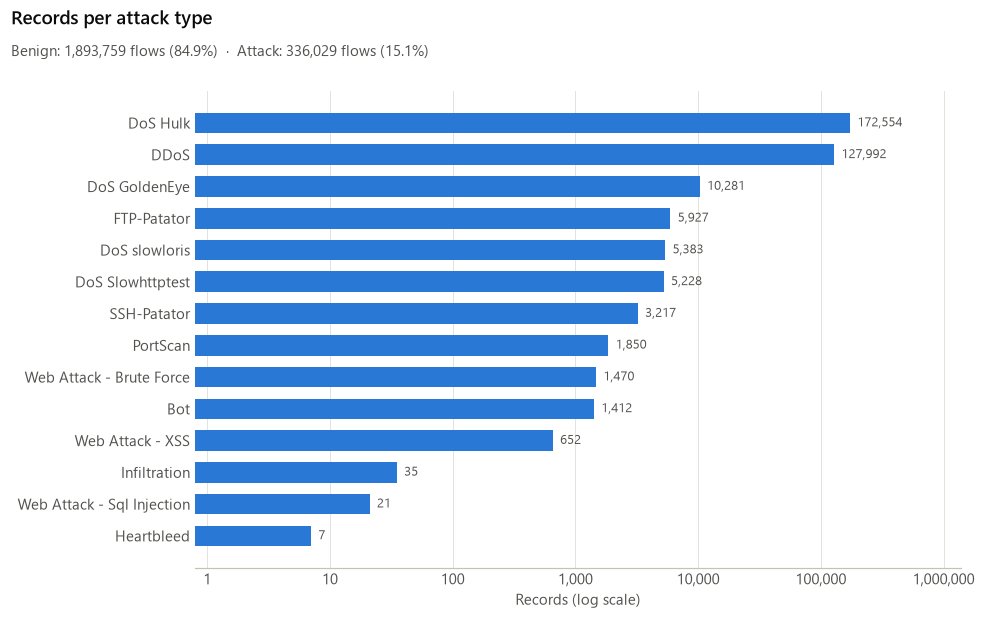

In [7]:
attack_counts = label_counts.drop("BENIGN").sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(attack_counts.index, attack_counts.values, color=MODEL_COLORS["Random Forest"], height=0.65)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Records (log scale)")
for bar, value in zip(bars, attack_counts.values):
    ax.text(value * 1.15, bar.get_y() + bar.get_height() / 2, f"{value:,}",
            va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(left=0.8, right=attack_counts.max() * 8)
fig.tight_layout()
fig_title(fig, "Records per attack type",
          f"Benign: {n_benign:,} flows ({n_benign / len(y) * 100:.1f}%)  ·  "
          f"Attack: {n_attack:,} flows ({n_attack / len(y) * 100:.1f}%)")
save_fig(fig, "01_class_distribution")

## 4. Modeller ve Değerlendirme Protokolü

| Model | Ayarlar | Seçim gerekçesi |
|---|---|---|
| Random Forest | 100 ağaç | Bagging tabanlı, eşik (threshold) kararlarıyla çalışan topluluk modeli |
| XGBoost | 200 ağaç, derinlik 8, öğrenme oranı 0.1, `subsample = colsample = 0.8` | Boosting tabanlı, güçlü tablo verisi modeli |
| MLP | 64–32 gizli katman, Adam, `batch_size = 1024`, erken durdurma | Sürekli karar yüzeyine sahip sinir ağı |

**Protokol**

- Her seed için veri yeniden **%80 eğitim / %20 test** olarak katmanlı biçimde bölünür. `StandardScaler` yalnızca eğitim kümesine fit edilir.
- Seed; bölmeyi, model başlangıcını ve pertürbasyonun rastgeleliğini birlikte belirler. Sonuçlar **3 seed üzerinden ortalama ± standart sapma** (örneklem std, `ddof = 1`) olarak raporlanır.
- Metrikler saldırı sınıfı (1) pozitif kabul edilerek hesaplanır: Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC (average precision), ayrıca TN / FP / FN / TP.

In [8]:
def make_model(name, seed):
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=seed)
    if name == "XGBoost":
        return XGBClassifier(
            n_estimators=200, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
            tree_method="hist", eval_metric="logloss", importance_type="gain", n_jobs=-1, random_state=seed,
        )
    if name == "MLP":
        return MLPClassifier(
            hidden_layer_sizes=(64, 32), batch_size=1024, learning_rate_init=1e-3, max_iter=100,
            early_stopping=True, validation_fraction=0.1, n_iter_no_change=5, random_state=seed,
        )
    raise ValueError(name)


def split_data(seed):
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)


def compute_metrics(y_true, proba):
    y_true = np.asarray(y_true)
    y_pred = (proba >= DECISION_THRESHOLD).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

## 5. Veri Sızıntısı Analizi

CIC-IDS2017 üzerinde %99'un üzerinde sonuç almak kolaydır. Bu başarının bir kısmı saldırı davranışından değil, veri setine özgü ipuçlarından kaynaklanabilir. Bu bölümde üç kontrol yapılır:

1. **Eğitim–test çakışması.** Test kümesindeki akışlardan kaçı eğitim kümesinde birebir yer alıyor? Tekilleştirme sonrası bu sayının 0 olması beklenir.
2. **Tek özellik ile ayrıştırma.** Her özellik tek başına skor olarak kullanıldığında elde edilen ROC-AUC. 1'e çok yakın değerler, modelin tek bir kısayola dayanabileceğini gösterir.
3. **`Destination Port` etkisi.** Saldırıların hangi portlara yoğunlaştığı ve port özellik olarak eklendiğinde sonucun ne kadar değiştiği.

In [9]:
X_tr, X_te, y_tr, y_te = split_data(SEEDS[0])

# 1) Eğitim–test çakışması
train_hashes = pd.util.hash_pandas_object(X_tr, index=False).values
test_hashes = pd.util.hash_pandas_object(X_te, index=False).values
n_overlap = int(np.isin(test_hashes, train_hashes).sum())
print(f"Test kümesinde eğitim kümesiyle birebir aynı olan akış sayısı: {n_overlap:,} / {len(X_te):,}")

# 2) Tek özellik ile ayrıştırma gücü
sample = X_tr.sample(min(200_000, len(X_tr)), random_state=0)
y_sample = y_tr.loc[sample.index]
single_auc = pd.Series({col: roc_auc_score(y_sample, sample[col]) for col in FEATURES})
single_auc = np.maximum(single_auc, 1 - single_auc).sort_values(ascending=False)

single_table = pd.DataFrame({"Feature": single_auc.index[:10], "Single-feature ROC-AUC": single_auc.values[:10]})
show_table(single_table, "Table 2 — Top 10 most discriminative single features", "leakage_single_feature_auc.csv")
print(f"Tek başına ROC-AUC > 0.95 olan özellik sayısı: {(single_auc > 0.95).sum()}")

Test kümesinde eğitim kümesiyle birebir aynı olan akış sayısı: 0 / 445,958


Feature,Single-feature ROC-AUC
Fwd IAT Std,0.8464
Fwd IAT Max,0.8411
Flow IAT Std,0.8404
Bwd Packet Length Std,0.8356
Fwd IAT Mean,0.8333
Flow IAT Max,0.8291
Flow Packets/s,0.8163
Fwd Packets/s,0.8153
Flow IAT Mean,0.8121
Fwd IAT Total,0.8064


Tek başına ROC-AUC > 0.95 olan özellik sayısı: 0


In [10]:
# 3) Destination Port: saldırıların port dağılımı
def top_ports(mask, k=5):
    share = ports[mask].value_counts(normalize=True).head(k) * 100
    return ", ".join(f"{int(p)} ({s:.1f}%)" for p, s in share.items())

port_rows = [{"Class": "Normal (BENIGN)", "Top destination ports": top_ports(labels == "BENIGN")}]
for attack in labels[labels != "BENIGN"].value_counts().index:
    port_rows.append({"Class": attack, "Top destination ports": top_ports(labels == attack, k=3)})
show_table(pd.DataFrame(port_rows), "Table 3 — Destination port concentration by class", "leakage_port_distribution.csv")

# Port özellik olarak eklendiğinde XGBoost sonucu
n_sub = min(ABLATION_TRAIN_SIZE, len(X_tr) - 1)
X_sub, _, y_sub, _ = train_test_split(X_tr, y_tr, train_size=n_sub, stratify=y_tr, random_state=SEEDS[0])

port_rows = []
for variant, with_port in [("Without Destination Port", False), ("With Destination Port", True)]:
    Xa_tr = X_sub.assign(**{"Destination Port": ports.loc[X_sub.index]}) if with_port else X_sub
    Xa_te = X_te.assign(**{"Destination Port": ports.loc[X_te.index]}) if with_port else X_te
    model = make_model("XGBoost", SEEDS[0]).fit(Xa_tr, y_sub)
    m = compute_metrics(y_te, model.predict_proba(Xa_te)[:, 1])
    row = {"Variant": variant, "Recall": m["Recall"], "F1": m["F1"], "PR-AUC": m["PR-AUC"], "FN": m["FN"]}
    if with_port:
        importance = pd.Series(model.feature_importances_, index=Xa_tr.columns).sort_values(ascending=False)
        row["Port importance rank"] = f"{importance.index.get_loc('Destination Port') + 1} / {len(importance)}"
    port_rows.append(row)

show_table(pd.DataFrame(port_rows).fillna("—"),
           f"Table 4 — Effect of Destination Port (XGBoost, {n_sub:,} training samples, seed {SEEDS[0]})",
           "leakage_port_effect.csv")

Class,Top destination ports
Normal (BENIGN),"53 (46.3%), 443 (24.6%), 80 (11.4%), 123 (1.1%), 22 (0.4%)"
DoS Hulk,80 (100.0%)
DDoS,"80 (100.0%), 64869 (0.0%), 64873 (0.0%)"
DoS GoldenEye,80 (100.0%)
FTP-Patator,"21 (100.0%), 80 (0.0%)"
DoS slowloris,80 (100.0%)
DoS Slowhttptest,80 (100.0%)
SSH-Patator,22 (100.0%)
PortScan,"80 (20.1%), 22 (13.1%), 21 (13.1%)"
Web Attack - Brute Force,80 (100.0%)


Variant,Recall,F1,PR-AUC,FN,Port importance rank
Without Destination Port,0.9971,0.9975,0.9999,198,—
With Destination Port,0.9980,0.9983,0.9999,135,9 / 65


## 6. Özellik Grupları, Tehdit Modeli ve Pertürbasyon Kısıtları

### 6.1 Özellik grupları

Özellikler ağ trafiğindeki anlamlarına göre dört gruba ayrılır: **Boyut** (paket ve bayt uzunlukları), **Zaman** (akış süresi, paketler arası süre (IAT), aktif/boşta süreleri), **Hız** (saniye başına bayt/paket) ve **Sayaç/Protokol** (paket sayıları, TCP bayrakları, başlık uzunlukları, pencere boyutu).

### 6.2 Tehdit modeli

- Saldırgan **yalnızca kendi saldırı akışlarını** değiştirir; normal trafik ve model değişmez. Bu nedenle pertürbasyon yalnızca test kümesindeki saldırı örneklerine uygulanır.
- Saldırgan yalnızca **kendi gönderdiği (ileri yön) paketleri** kontrol eder. Bu paketlere dolgu (padding) ekleyebilir ve gönderim aralarına gecikme koyabilir. Sunucu yanıtlarının (geri yön) boyutunu değiştiremez.
- Saldırının işlevini bozmamak için paket **eklenmez veya silinmez** ve hiçbir değer **azaltılmaz**. Paket kısaltmak yükü bozar; zamanı kısaltmak ağın izin verdiğinden hızlı göndermek demektir.

### 6.3 Pertürbasyon ve korunan kısıtlar

Pertürbasyon ölçeklenmiş uzayda değil, **ham (fiziksel) birimlerde göreli olarak** uygulanır. Ölçeklenmiş uzayda aynı ε değeri, çok çarpık dağılımlı özelliklerde birkaç bayta, diğerlerinde saniyelere karşılık gelir ve raporda yorumlanamaz. Göreli bütçe ise doğrudan okunur: ε = 0.25, "paket boyutları ve/veya süreler en fazla %25 artırıldı" demektir.

Her akış için iki katsayı seçilir: boyut katsayısı `s ∈ [1, 1+ε]` ve zaman katsayısı `t ∈ [1, 1+ε]`. Ardından:

| Özellikler | Güncelleme | Korunan kısıt |
|---|---|---|
| İleri yön boyutları (toplam, min, max, ortalama, std, segment, subflow) | `× s` | Her pakete orantılı padding; min ≤ ortalama ≤ max korunur |
| Çift yön türetilmişleri (`Packet Length Mean`, `Average Packet Size`, `Max Packet Length`) | Eklenen bayttan yeniden hesaplanır | Toplam bayt ve paket sayısıyla tutarlılık |
| Zaman özellikleri (süre, IAT, aktif, boşta) | `× t` | Akışın tümüyle yavaşlatılması |
| Hız özellikleri (`Flow Bytes/s`, `*Packets/s`) | Bayt ve süre değişiminden yeniden hesaplanır | `hız = miktar / süre` |
| Paket sayıları, bayraklar, başlıklar, geri yön boyutları | Değişmez | Protokol ve sunucu davranışı |

Son olarak tam sayı özellikler yuvarlanır ve katsayılar, hiçbir özellik **eğitim kümesinde gözlenen maksimum değeri aşmayacak** şekilde sınırlandırılır (geçerli özellik aralığı).

### 6.4 Saldırgan türleri

- **Rastgele:** Her akış için `s` ve `t` değerleri `1 + U(0, ε)` dağılımından çekilir. Modelden bilgi almayan, hedefsiz bir değişikliktir.
- **Uyarlamalı (kara kutu):** Saldırgan modelin iç yapısını bilmez ancak skorunu sorgulayabilir. Her akış için `{1, …, 1+ε}` aralığındaki `ADAPTIVE_GRID` katsayıyı (ve kombinasyonlarını) dener, saldırı olasılığını en düşük yapan seçeneği kullanır. Gradyana ihtiyaç duymadığı için üç modele de aynı şekilde uygulanır.

In [11]:
def present(columns):
    return [c for c in columns if c in FEATURES]


SIZE_FEATURES = present([
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Fwd Packet Length Max", "Fwd Packet Length Min", "Fwd Packet Length Mean", "Fwd Packet Length Std",
    "Bwd Packet Length Max", "Bwd Packet Length Min", "Bwd Packet Length Mean", "Bwd Packet Length Std",
    "Min Packet Length", "Max Packet Length", "Packet Length Mean", "Packet Length Std", "Packet Length Variance",
    "Average Packet Size", "Avg Fwd Segment Size", "Avg Bwd Segment Size", "Subflow Fwd Bytes", "Subflow Bwd Bytes",
])
TIME_FEATURES = present([
    "Flow Duration",
    "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
    "Fwd IAT Total", "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min",
    "Bwd IAT Total", "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min",
    "Active Mean", "Active Std", "Active Max", "Active Min",
    "Idle Mean", "Idle Std", "Idle Max", "Idle Min",
])
RATE_FEATURES = present(["Flow Bytes/s", "Flow Packets/s", "Fwd Packets/s", "Bwd Packets/s"])
COUNT_PROTOCOL_FEATURES = [c for c in FEATURES if c not in SIZE_FEATURES + TIME_FEATURES + RATE_FEATURES]

FEATURE_GROUPS = {
    "Size": SIZE_FEATURES, "Time": TIME_FEATURES,
    "Rate": RATE_FEATURES, "Count/Protocol": COUNT_PROTOCOL_FEATURES,
}
FEATURE_TO_GROUP = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}

# Saldırganın değiştirebildiği / dolaylı olarak değişen özellikler
FWD_SIZE_SCALED = present([
    "Total Length of Fwd Packets", "Fwd Packet Length Max", "Fwd Packet Length Min",
    "Fwd Packet Length Mean", "Fwd Packet Length Std", "Avg Fwd Segment Size", "Subflow Fwd Bytes",
])
BIDIR_SIZE_DERIVED = present(["Max Packet Length", "Packet Length Mean", "Average Packet Size"])
MODIFIED_FEATURES = FWD_SIZE_SCALED + BIDIR_SIZE_DERIVED + TIME_FEATURES + RATE_FEATURES
FIXED_SIZE_FEATURES = [c for c in SIZE_FEATURES if c not in FWD_SIZE_SCALED + BIDIR_SIZE_DERIVED]

group_table = pd.DataFrame([
    {"Group": "Size — forward direction", "Number of features": len(FWD_SIZE_SCALED), "Attacker can modify": "Yes (padding)",
     "Update rule": "× s", "Feature names": ", ".join(FWD_SIZE_SCALED)},
    {"Group": "Size — bidirectional derived", "Number of features": len(BIDIR_SIZE_DERIVED), "Attacker can modify": "Indirectly",
     "Update rule": "Recomputed", "Feature names": ", ".join(BIDIR_SIZE_DERIVED)},
    {"Group": "Size — backward and dispersion", "Number of features": len(FIXED_SIZE_FEATURES), "Attacker can modify": "No",
     "Update rule": "Unchanged", "Feature names": ", ".join(FIXED_SIZE_FEATURES)},
    {"Group": "Time", "Number of features": len(TIME_FEATURES), "Attacker can modify": "Yes (delay)",
     "Update rule": "× t", "Feature names": ", ".join(TIME_FEATURES)},
    {"Group": "Rate", "Number of features": len(RATE_FEATURES), "Attacker can modify": "Indirectly",
     "Update rule": "Recomputed", "Feature names": ", ".join(RATE_FEATURES)},
    {"Group": "Count/Protocol", "Number of features": len(COUNT_PROTOCOL_FEATURES), "Attacker can modify": "No",
     "Update rule": "Unchanged", "Feature names": ", ".join(COUNT_PROTOCOL_FEATURES)},
])
show_table(group_table, "Table 5 — Feature groups and perturbation rules", "feature_groups.csv")

Group,Number of features,Attacker can modify,Update rule,Feature names
Size — forward direction,7,Yes (padding),× s,"Total Length of Fwd Packets, Fwd Packet Length Max, Fwd Packet Length Min, Fwd Packet Length Mean, Fwd Packet Length Std, Avg Fwd Segment Size, Subflow Fwd Bytes"
Size — bidirectional derived,3,Indirectly,Recomputed,"Max Packet Length, Packet Length Mean, Average Packet Size"
Size — backward and dispersion,10,No,Unchanged,"Total Length of Bwd Packets, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Bwd Packet Length Std, Min Packet Length, Packet Length Std, Packet Length Variance, Avg Bwd Segment Size, Subflow Bwd Bytes"
Time,23,Yes (delay),× t,"Flow Duration, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Fwd IAT Total, Fwd IAT Mean, Fwd IAT Std, Fwd IAT Max, Fwd IAT Min, Bwd IAT Total, Bwd IAT Mean, Bwd IAT Std, Bwd IAT Max, Bwd IAT Min, Active Mean, Active Std, Active Max, Active Min, Idle Mean, Idle Std, Idle Max, Idle Min"
Rate,4,Indirectly,Recomputed,"Flow Bytes/s, Flow Packets/s, Fwd Packets/s, Bwd Packets/s"
Count/Protocol,17,No,Unchanged,"Total Fwd Packets, Total Backward Packets, Fwd PSH Flags, Fwd URG Flags, Fwd Header Length, Bwd Header Length, FIN Flag Count, RST Flag Count, PSH Flag Count, ACK Flag Count, URG Flag Count, ECE Flag Count, Down/Up Ratio, Init_Win_bytes_forward, Init_Win_bytes_backward, act_data_pkt_fwd, min_seg_size_forward"


In [12]:
def max_allowed_factor(X_raw, columns, upper):
    # Her akış için, verilen sütunların hiçbiri eğitim maksimumunu aşmayacak şekilde en büyük katsayı.
    if not columns:
        return np.full(len(X_raw), np.inf)
    values = X_raw[columns].to_numpy()
    limits = upper[columns].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(values > 0, limits / values, np.inf)
    return np.maximum(ratio.min(axis=1), 1.0)


def apply_perturbation(X_raw, size_factor, time_factor, bounds):
    # Saldırı akışlarına (ham birimlerde) ağ kısıtlarını koruyan pertürbasyon uygular.
    lower, upper = bounds
    X_adv = X_raw.copy()
    n = len(X_adv)
    s = np.broadcast_to(np.asarray(size_factor, dtype=float), (n,)).copy()
    t = np.broadcast_to(np.asarray(time_factor, dtype=float), (n,)).copy()

    # Geçerli aralık: katsayılar eğitim maksimumunu aşmayacak şekilde sınırlandırılır
    s = np.minimum(s, max_allowed_factor(X_adv, FWD_SIZE_SCALED, upper))
    t = np.minimum(t, max_allowed_factor(X_adv, TIME_FEATURES, upper))

    # Boyut: ileri yöndeki her pakete orantılı padding
    fwd_bytes_old = X_adv["Total Length of Fwd Packets"].to_numpy().copy()
    X_adv[FWD_SIZE_SCALED] = X_adv[FWD_SIZE_SCALED].to_numpy() * s[:, None]
    added_bytes = X_adv["Total Length of Fwd Packets"].to_numpy() - fwd_bytes_old

    # Çift yön türetilmiş boyutlar: eklenen bayt tüm paketlere bölünür, en büyük paket güncellenir
    n_packets = (X_adv["Total Fwd Packets"] + X_adv["Total Backward Packets"]).to_numpy()
    for col in present(["Packet Length Mean", "Average Packet Size"]):
        X_adv[col] = X_adv[col].to_numpy() + added_bytes / np.maximum(n_packets, 1)
    if "Max Packet Length" in X_adv:
        X_adv["Max Packet Length"] = np.maximum(X_adv["Max Packet Length"], X_adv["Fwd Packet Length Max"])

    # Zaman: akış t katı yavaşlatılır
    T = X_adv[TIME_FEATURES].to_numpy()
    X_adv[TIME_FEATURES] = np.where(T > 0, T * t[:, None], T)

    # Hız: yeni bayt miktarı ve yeni süreden yeniden hesaplanır
    total_bytes_old = fwd_bytes_old + X_adv["Total Length of Bwd Packets"].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        byte_ratio = np.where(total_bytes_old > 0, (total_bytes_old + added_bytes) / total_bytes_old, 1.0)
    if "Flow Bytes/s" in X_adv:
        X_adv["Flow Bytes/s"] = X_adv["Flow Bytes/s"].to_numpy() * byte_ratio / t
    for col in present(["Flow Packets/s", "Fwd Packets/s", "Bwd Packets/s"]):
        X_adv[col] = X_adv[col].to_numpy() / t

    # Tam sayı özellikler yuvarlanır, değişen özellikler geçerli aralıkta tutulur
    int_modified = [c for c in MODIFIED_FEATURES if c in INT_COLS]
    X_adv[int_modified] = np.round(X_adv[int_modified].to_numpy())
    X_adv[MODIFIED_FEATURES] = X_adv[MODIFIED_FEATURES].clip(
        lower=lower[MODIFIED_FEATURES], upper=upper[MODIFIED_FEATURES], axis=1
    )
    return X_adv


def attack_probabilities(attacker, group, eps, X_att, bounds, score_fn, rng):
    # Seçilen saldırgan ve özellik grubu için pertürbe edilmiş saldırı akışlarının model skorlarını döndürür.
    n = len(X_att)
    use_size, use_time = "Size" in group, "Time" in group

    if attacker == "Random":
        s = 1 + rng.uniform(0, eps, n) if use_size else np.ones(n)
        t = 1 + rng.uniform(0, eps, n) if use_time else np.ones(n)
        return score_fn(apply_perturbation(X_att, s, t, bounds))

    # Uyarlamalı kara kutu saldırgan: aday katsayıları sorgular, en düşük skoru veren seçeneği tutar
    levels = 1 + np.linspace(0, eps, ADAPTIVE_GRID)
    best_p = np.full(n, np.inf)
    for s in (levels if use_size else [1.0]):
        for t in (levels if use_time else [1.0]):
            best_p = np.minimum(best_p, score_fn(apply_perturbation(X_att, s, t, bounds)))
    return best_p

### 6.5 Kısıt kontrolü

Pertürbasyon fonksiyonunun yukarıdaki kısıtları gerçekten koruduğu, saldırı akışlarından alınan bir örnek üzerinde en yüksek bütçeyle (`s = t = 1 + max(ε)`) test edilir.

In [13]:
X_demo = X[y == 1].sample(min(20_000, int((y == 1).sum())), random_state=0)
demo_bounds = (X.min(), X.max())
eps_max = max(EPSILONS)
X_adv_demo = apply_perturbation(X_demo, 1 + eps_max, 1 + eps_max, demo_bounds)


def fwd_order_ok(df):
    return ((df["Fwd Packet Length Min"] <= df["Fwd Packet Length Mean"] + 1e-6) &
            (df["Fwd Packet Length Mean"] <= df["Fwd Packet Length Max"] + 1e-6)).mean()


unchanged = COUNT_PROTOCOL_FEATURES + FIXED_SIZE_FEATURES
int_modified = [c for c in MODIFIED_FEATURES if c in INT_COLS]
checks = [
    ("No negative values in modified features", bool((X_adv_demo[MODIFIED_FEATURES] >= 0).all().all())),
    ("Values within the training range",
     bool(((X_adv_demo[MODIFIED_FEATURES] >= demo_bounds[0][MODIFIED_FEATURES]) &
           (X_adv_demo[MODIFIED_FEATURES] <= demo_bounds[1][MODIFIED_FEATURES])).all().all())),
    ("Integer features remain integers",
     bool(np.allclose(X_adv_demo[int_modified], np.round(X_adv_demo[int_modified])))),
    ("Packet counts, flags and backward sizes unchanged", bool(X_adv_demo[unchanged].equals(X_demo[unchanged]))),
    ("Size and time features only increased",
     bool((X_adv_demo[FWD_SIZE_SCALED + TIME_FEATURES] >= X_demo[FWD_SIZE_SCALED + TIME_FEATURES] - 1e-6).all().all())),
    ("Fwd min ≤ mean ≤ max order preserved", bool(fwd_order_ok(X_adv_demo) >= fwd_order_ok(X_demo))),
    ("Max Packet Length ≥ Fwd Packet Length Max",
     bool((X_adv_demo["Max Packet Length"] >= X_adv_demo["Fwd Packet Length Max"] - 1e-6).all())),
]
check_table = pd.DataFrame(checks, columns=["Constraint", "Satisfied"])
check_table["Satisfied"] = check_table["Satisfied"].map({True: "✓", False: "✗"})
show_table(check_table, f"Table 6 — Perturbation constraint check ({len(X_demo):,} attack flows, ε = {eps_max:.0%})",
           "perturbation_constraint_check.csv")


def median_increase(col):
    before, after = X_demo[col], X_adv_demo[col]
    mask = before > 0
    return float(((after[mask] / before[mask]) - 1).median() * 100)


print("Gerçekleşen medyan artış (sınırlar nedeniyle bütçenin altında kalabilir):")
for col in ["Total Length of Fwd Packets", "Fwd Packet Length Max", "Flow Duration", "Flow IAT Mean"]:
    print(f"  {col:<30} %{median_increase(col):.1f}")

Constraint,Satisfied
No negative values in modified features,✓
Values within the training range,✓
Integer features remain integers,✓
"Packet counts, flags and backward sizes unchanged",✓
Size and time features only increased,✓
Fwd min ≤ mean ≤ max order preserved,✓
Max Packet Length ≥ Fwd Packet Length Max,✓


Gerçekleşen medyan artış (sınırlar nedeniyle bütçenin altında kalabilir):
  Total Length of Fwd Packets    %100.0
  Fwd Packet Length Max          %100.0
  Flow Duration                  %100.0
  Flow IAT Mean                  %100.0


## 7. Deneyler A–C

Tüm deneyler tek bir döngüde çalışır. Her seed için:

1. Veri bölünür, ölçekleyici eğitim kümesine fit edilir, üç model eğitilir.
2. **Deney A:** Model temiz test verisinde değerlendirilir.
3. **Deney B:** Test kümesindeki saldırı akışları her `(saldırgan, özellik grubu, ε)` kombinasyonu için pertürbe edilir. Normal akışlar değişmeden kalır ve metrikler tüm test kümesi üzerinden hesaplanır.
4. **Deney C:** A ve B sonuçları modeller arasında karşılaştırılır ve modeller sıralanır (7.3).

> **Not:** Bu hücre tam veriyle uzun sürer (RF ve MLP eğitimi + her model için yüzlerce tahmin turu). İlerleme her model için yazdırılır.

In [14]:
baseline_rows, perturbation_rows, importance_rows = [], [], []
start = time.time()

for seed in SEEDS:
    X_tr, X_te, y_tr, y_te = split_data(seed)
    scaler = StandardScaler().fit(X_tr)
    Xs_tr = scaler.transform(X_tr).astype(np.float32)
    Xs_te = scaler.transform(X_te).astype(np.float32)
    bounds = (X_tr.min(), X_tr.max())

    is_attack = (y_te == 1).to_numpy()
    X_att = X_te[is_attack]
    y_eval = np.r_[np.zeros((~is_attack).sum(), dtype=np.int8), np.ones(is_attack.sum(), dtype=np.int8)]
    rng = np.random.default_rng(seed)

    for name in MODEL_NAMES:
        t0 = time.time()
        model = make_model(name, seed).fit(Xs_tr, y_tr.to_numpy())

        def score_fn(X_raw, model=model):
            return model.predict_proba(scaler.transform(X_raw).astype(np.float32))[:, 1]

        # Deney A
        p_clean = model.predict_proba(Xs_te)[:, 1]
        baseline_rows.append({"Seed": seed, "Model": name, **compute_metrics(y_te, p_clean)})
        if hasattr(model, "feature_importances_"):
            imp = model.feature_importances_ / model.feature_importances_.sum()
            importance_rows += [{"Seed": seed, "Model": name, "Feature": f, "Importance": v} for f, v in zip(FEATURES, imp)]

        # Deney B
        p_benign = p_clean[~is_attack]
        for attacker in ATTACKERS:
            for group in SCENARIO_GROUPS:
                for eps in EPSILONS:
                    if eps == 0:
                        p_att = p_clean[is_attack]
                    else:
                        p_att = attack_probabilities(attacker, group, eps, X_att, bounds, score_fn, rng)
                    metrics = compute_metrics(y_eval, np.r_[p_benign, p_att])
                    perturbation_rows.append({"Seed": seed, "Model": name, "Attacker": attacker,
                                              "Group": group, "Epsilon": eps, **metrics})

        print(f"seed {seed:<5} {name:<14} tamamlandı  ({time.time() - t0:,.0f} sn)")
        del model

baseline_df = pd.DataFrame(baseline_rows)
perturbation_df = pd.DataFrame(perturbation_rows)
importance_df = pd.DataFrame(importance_rows)
baseline_df.to_csv(METRICS_DIR / "raw_experiment_A_per_seed.csv", index=False, encoding="utf-8-sig")
perturbation_df.to_csv(METRICS_DIR / "raw_experiment_B_per_seed.csv", index=False, encoding="utf-8-sig")
importance_df.to_csv(METRICS_DIR / "raw_feature_importance_per_seed.csv", index=False, encoding="utf-8-sig")
print(f"\nToplam süre: {(time.time() - start) / 60:,.1f} dk")

seed 42    Random Forest  tamamlandı  (161 sn)
seed 42    XGBoost        tamamlandı  (65 sn)
seed 42    MLP            tamamlandı  (115 sn)
seed 100   Random Forest  tamamlandı  (158 sn)
seed 100   XGBoost        tamamlandı  (66 sn)
seed 100   MLP            tamamlandı  (75 sn)
seed 2024  Random Forest  tamamlandı  (165 sn)
seed 2024  XGBoost        tamamlandı  (66 sn)
seed 2024  MLP            tamamlandı  (109 sn)

Toplam süre: 16.6 dk


### 7.1 Deney A — Baseline performansı

Modeller temiz eğitim verisiyle eğitilir ve değiştirilmemiş test verisinde değerlendirilir.

In [15]:
COUNT_COLS = ["FN", "FP"]
grouped = baseline_df.groupby("Model")[METRIC_COLS + COUNT_COLS]
baseline_table = format_pm(grouped.mean().loc[MODEL_NAMES], grouped.std().loc[MODEL_NAMES],
                           digits={**{m: 4 for m in METRIC_COLS}, "FN": 1, "FP": 1}).reset_index()
show_table(baseline_table, f"Table 7 — Experiment A: performance on clean test data ({len(SEEDS)} seeds, mean ± std)",
           "experiment_A_baseline.csv")

Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,FN,FP
Random Forest,0.9991 ± 0.0001,0.9984 ± 0.0000,0.9958 ± 0.0004,0.9971 ± 0.0002,1.0000 ± 0.0000,0.9999 ± 0.0000,280.7 ± 25.6,106.0 ± 1.0
XGBoost,0.9994 ± 0.0000,0.9983 ± 0.0002,0.9977 ± 0.0003,0.9980 ± 0.0001,1.0000 ± 0.0000,1.0000 ± 0.0000,156.7 ± 17.6,112.3 ± 11.5
MLP,0.9961 ± 0.0004,0.9896 ± 0.0019,0.9844 ± 0.0009,0.9870 ± 0.0014,0.9997 ± 0.0000,0.9988 ± 0.0002,"1,051.0 ± 61.7",693.7 ± 127.2


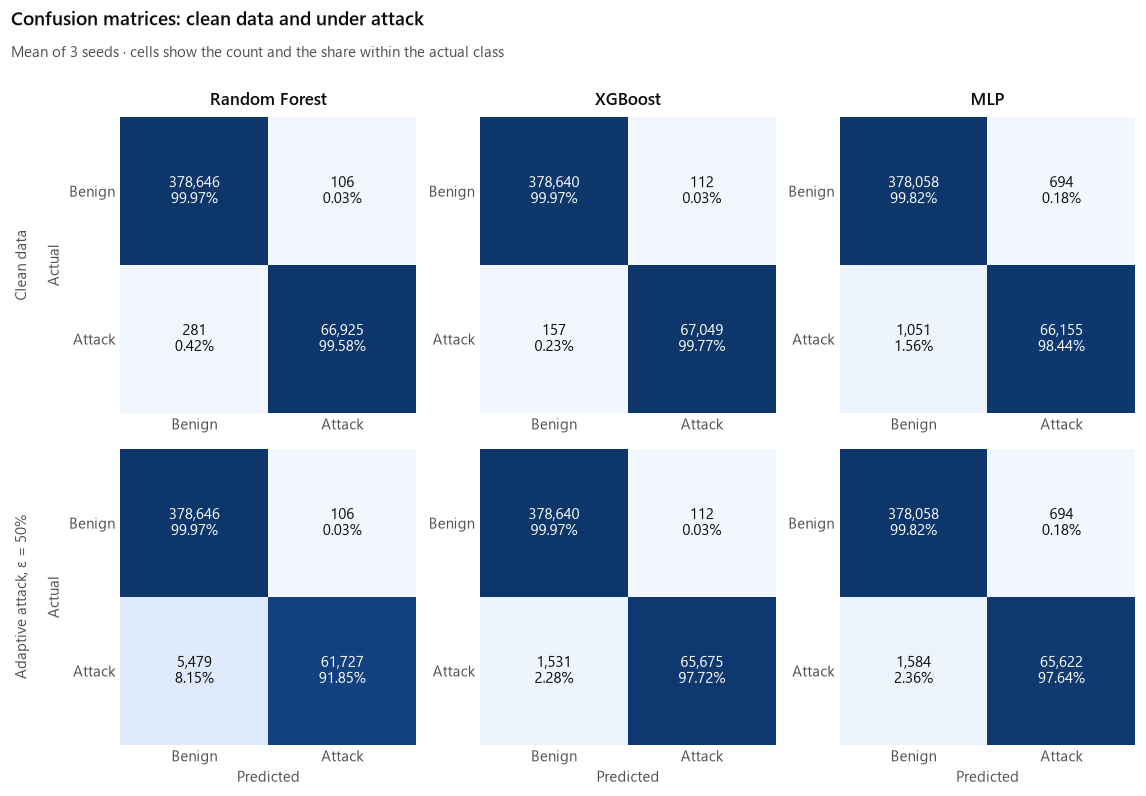

In [16]:
def mean_confusion(df):
    m = df[["TN", "FP", "FN", "TP"]].mean()
    return np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])


def plot_confusion_grid(rows, title, subtitle, filename):
    # rows: [(satır başlığı, {model: 2x2 matris})]
    fig, axes = plt.subplots(len(rows), len(MODEL_NAMES), figsize=(10.5, 3.3 * len(rows)), squeeze=False)
    for r, (row_title, matrices) in enumerate(rows):
        for c, name in enumerate(MODEL_NAMES):
            ax = axes[r, c]
            cm = matrices[name]
            row_share = cm / cm.sum(axis=1, keepdims=True)
            ax.imshow(row_share, cmap=BLUE_SEQ, vmin=0, vmax=1)
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, f"{cm[i, j]:,.0f}\n{row_share[i, j] * 100:.2f}%", ha="center", va="center",
                            fontsize=9.5, color="white" if row_share[i, j] > 0.55 else INK)
            ax.set_xticks([0, 1], ["Benign", "Attack"])
            ax.set_yticks([0, 1], ["Benign", "Attack"])
            ax.grid(False)
            for spine in ax.spines.values():
                spine.set_visible(False)
            ax.set_title(name if r == 0 else "", loc="center")
            ax.set_xlabel("Predicted" if r == len(rows) - 1 else "")
            ax.set_ylabel(f"{row_title}\n\nActual" if c == 0 else "")
    fig.tight_layout()
    fig_title(fig, title, subtitle)
    save_fig(fig, filename)


ref = perturbation_df[(perturbation_df["Attacker"] == "Adaptive") &
                      (perturbation_df["Group"] == "Size+Time") & (perturbation_df["Epsilon"] == EPS_REF)]
plot_confusion_grid(
    [("Clean data", {n: mean_confusion(baseline_df[baseline_df["Model"] == n]) for n in MODEL_NAMES}),
     (f"Adaptive attack, ε = {EPS_REF * 100:.0f}%", {n: mean_confusion(ref[ref["Model"] == n]) for n in MODEL_NAMES})],
    "Confusion matrices: clean data and under attack",
    f"Mean of {len(SEEDS)} seeds · cells show the count and the share within the actual class",
    "02_confusion_matrix",
)

### 7.2 Deney B — Pertürbasyon duyarlılığı

Pertürbasyon bütçesi ε arttıkça saldırı sınıfındaki Recall ve F1 değerlerinin değişimi incelenir. Gölgeli alanlar seedler arasındaki ±1 standart sapmayı gösterir.

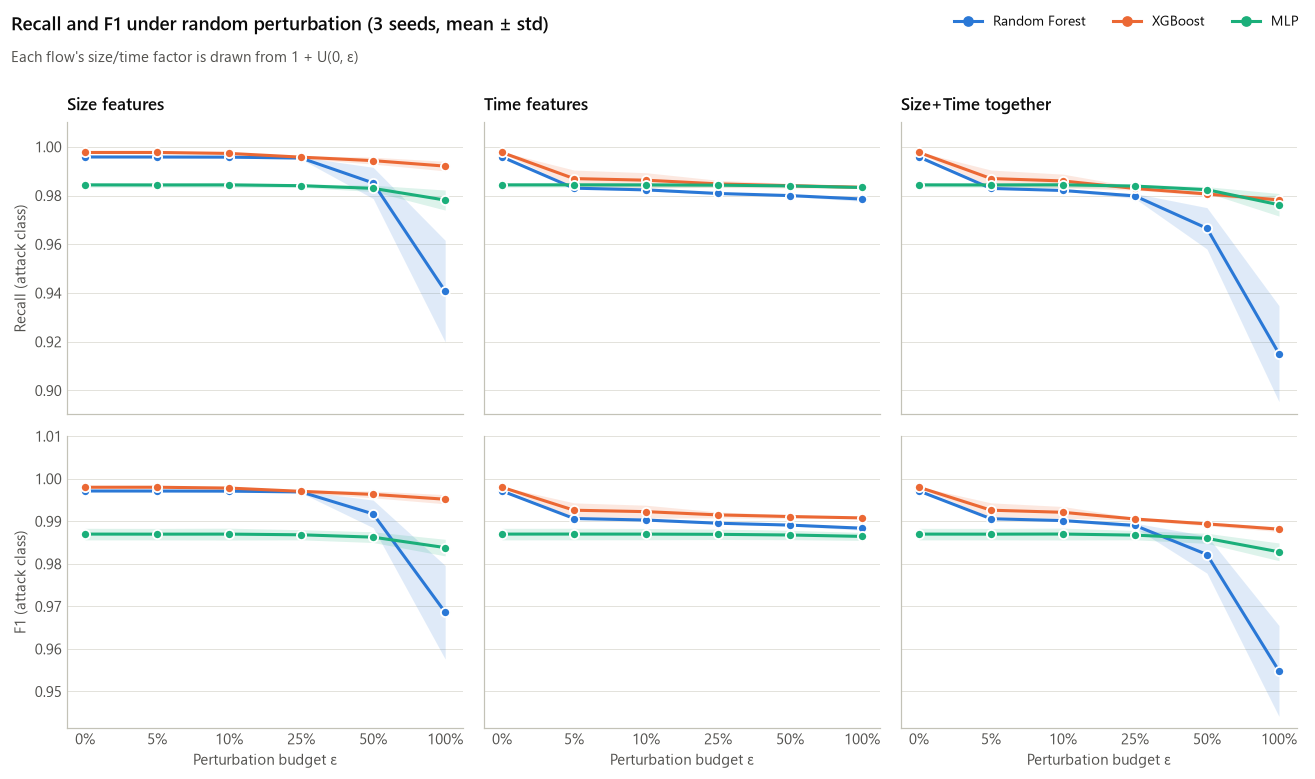

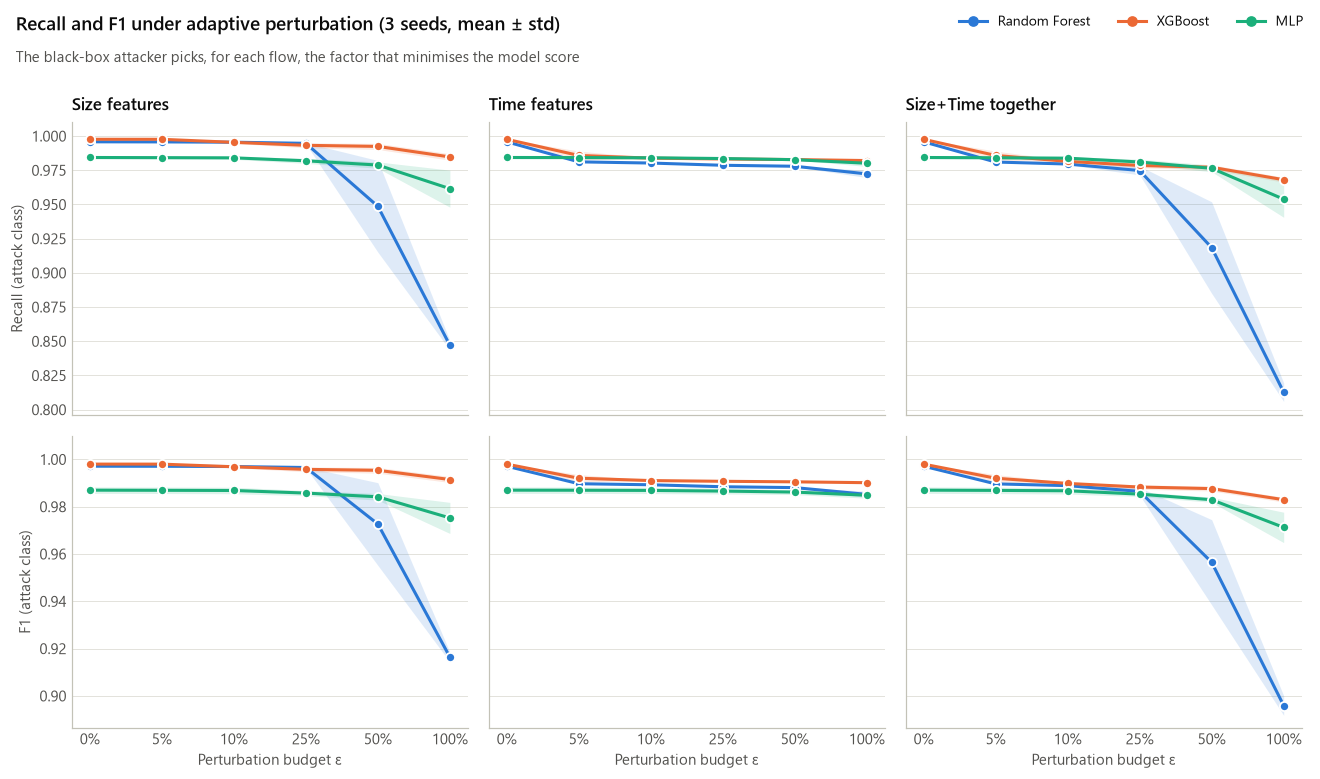

In [17]:
agg = (perturbation_df.groupby(["Attacker", "Group", "Model", "Epsilon"])[METRIC_COLS + ["FN"]]
       .agg(["mean", "std"]))


def plot_sensitivity(attacker, filename):
    eps_labels = [f"{e * 100:.0f}%" for e in EPSILONS]
    x = np.arange(len(EPSILONS))
    fig, axes = plt.subplots(2, len(SCENARIO_GROUPS), figsize=(12, 6.4), sharey="row", sharex=True)
    for c, group in enumerate(SCENARIO_GROUPS):
        for r, metric in enumerate(["Recall", "F1"]):
            ax = axes[r, c]
            for name in MODEL_NAMES:
                d = agg.loc[(attacker, group, name)]
                mean, std = d[(metric, "mean")].to_numpy(), d[(metric, "std")].fillna(0).to_numpy()
                ax.fill_between(x, mean - std, np.minimum(mean + std, 1), color=MODEL_COLORS[name], alpha=0.15, linewidth=0)
                ax.plot(x, mean, color=MODEL_COLORS[name], marker="o", markeredgecolor="white", markeredgewidth=1.2,
                        label=name)
            ax.set_xticks(x, eps_labels)
            if r == 0:
                ax.set_title(group + (" features" if group != "Size+Time" else " together"))
            if c == 0:
                ax.set_ylabel(f"{metric} (attack class)")
            if r == 1:
                ax.set_xlabel("Perturbation budget ε")
    for r in range(2):
        low = min(ax.get_ylim()[0] for ax in axes[r])
        axes[r, 0].set_ylim(max(0, low), 1.01)
    fig.tight_layout()
    top_legend(fig, [Line2D([], [], color=MODEL_COLORS[n], marker="o", label=n) for n in MODEL_NAMES])
    subtitle =("Each flow's size/time factor is drawn from 1 + U(0, ε)"
                if attacker == "Random" else
                "The black-box attacker picks, for each flow, the factor that minimises the model score")
    fig_title(fig, f"Recall and F1 under {attacker.lower()} perturbation ({len(SEEDS)} seeds, mean ± std)", subtitle)
    save_fig(fig, filename)


plot_sensitivity("Random", "03_sensitivity_random")
plot_sensitivity("Adaptive", "04_sensitivity_adaptive")

In [18]:
# Tüm seviyeler için ayrıntılı tablolar: satırlar senaryo × model, sütunlar ε (ortalama ± std)
for suffix, metric, digits, file_key in [("a", "Recall", 4, "recall"), ("b", "F1", 4, "f1"),
                                         ("c", "FN", 0, "fn"), ("d", "PR-AUC", 4, "pr_auc")]:
    g = perturbation_df.groupby(["Attacker", "Group", "Model", "Epsilon"], sort=False)[[metric]]
    pivot = format_pm(g.mean(), g.std(), digits=digits)[metric].unstack("Epsilon")
    pivot.columns = [f"ε = {e * 100:.0f}%" for e in pivot.columns]
    show_table(pivot.reset_index(), f"Table 8{suffix} — Experiment B: {metric} (mean ± std)",
               f"experiment_B_{file_key}.csv")

Attacker,Group,Model,ε = 0%,ε = 5%,ε = 10%,ε = 25%,ε = 50%,ε = 100%
Random,Size,Random Forest,0.9958 ± 0.0004,0.9958 ± 0.0004,0.9958 ± 0.0004,0.9954 ± 0.0005,0.9852 ± 0.0064,0.9408 ± 0.0208
Random,Size,XGBoost,0.9977 ± 0.0003,0.9977 ± 0.0003,0.9973 ± 0.0003,0.9957 ± 0.0006,0.9943 ± 0.0014,0.9921 ± 0.0020
Random,Size,MLP,0.9844 ± 0.0009,0.9843 ± 0.0009,0.9844 ± 0.0010,0.9840 ± 0.0007,0.9829 ± 0.0013,0.9781 ± 0.0041
Random,Time,Random Forest,0.9958 ± 0.0004,0.9830 ± 0.0002,0.9823 ± 0.0005,0.9808 ± 0.0003,0.9800 ± 0.0004,0.9785 ± 0.0009
Random,Time,XGBoost,0.9977 ± 0.0003,0.9870 ± 0.0035,0.9863 ± 0.0031,0.9848 ± 0.0015,0.9840 ± 0.0009,0.9834 ± 0.0005
Random,Time,MLP,0.9844 ± 0.0009,0.9844 ± 0.0009,0.9844 ± 0.0009,0.9842 ± 0.0008,0.9839 ± 0.0004,0.9833 ± 0.0003
Random,Size+Time,Random Forest,0.9958 ± 0.0004,0.9829 ± 0.0003,0.9821 ± 0.0002,0.9798 ± 0.0010,0.9665 ± 0.0085,0.9151 ± 0.0197
Random,Size+Time,XGBoost,0.9977 ± 0.0003,0.9870 ± 0.0035,0.9860 ± 0.0028,0.9829 ± 0.0007,0.9806 ± 0.0007,0.9782 ± 0.0009
Random,Size+Time,MLP,0.9844 ± 0.0009,0.9843 ± 0.0009,0.9844 ± 0.0011,0.9839 ± 0.0008,0.9824 ± 0.0012,0.9762 ± 0.0046
Adaptive,Size,Random Forest,0.9958 ± 0.0004,0.9957 ± 0.0004,0.9955 ± 0.0004,0.9947 ± 0.0004,0.9487 ± 0.0335,0.8471 ± 0.0034


Attacker,Group,Model,ε = 0%,ε = 5%,ε = 10%,ε = 25%,ε = 50%,ε = 100%
Random,Size,Random Forest,0.9971 ± 0.0002,0.9971 ± 0.0002,0.9971 ± 0.0002,0.9969 ± 0.0002,0.9917 ± 0.0032,0.9686 ± 0.0110
Random,Size,XGBoost,0.9980 ± 0.0001,0.9980 ± 0.0001,0.9978 ± 0.0002,0.9970 ± 0.0004,0.9963 ± 0.0008,0.9952 ± 0.0011
Random,Size,MLP,0.9870 ± 0.0014,0.9870 ± 0.0014,0.9870 ± 0.0014,0.9868 ± 0.0012,0.9863 ± 0.0013,0.9838 ± 0.0020
Random,Time,Random Forest,0.9971 ± 0.0002,0.9906 ± 0.0001,0.9903 ± 0.0003,0.9895 ± 0.0002,0.9891 ± 0.0002,0.9884 ± 0.0005
Random,Time,XGBoost,0.9980 ± 0.0001,0.9926 ± 0.0017,0.9923 ± 0.0015,0.9915 ± 0.0007,0.9911 ± 0.0004,0.9908 ± 0.0002
Random,Time,MLP,0.9870 ± 0.0014,0.9870 ± 0.0014,0.9870 ± 0.0013,0.9869 ± 0.0012,0.9868 ± 0.0011,0.9864 ± 0.0009
Random,Size+Time,Random Forest,0.9971 ± 0.0002,0.9906 ± 0.0002,0.9902 ± 0.0001,0.9890 ± 0.0005,0.9822 ± 0.0044,0.9548 ± 0.0107
Random,Size+Time,XGBoost,0.9980 ± 0.0001,0.9926 ± 0.0017,0.9921 ± 0.0014,0.9905 ± 0.0003,0.9894 ± 0.0004,0.9881 ± 0.0006
Random,Size+Time,MLP,0.9870 ± 0.0014,0.9870 ± 0.0013,0.9870 ± 0.0014,0.9867 ± 0.0011,0.9860 ± 0.0012,0.9828 ± 0.0021
Adaptive,Size,Random Forest,0.9971 ± 0.0002,0.9971 ± 0.0002,0.9970 ± 0.0002,0.9966 ± 0.0002,0.9727 ± 0.0175,0.9164 ± 0.0020


Attacker,Group,Model,ε = 0%,ε = 5%,ε = 10%,ε = 25%,ε = 50%,ε = 100%
Random,Size,Random Forest,281 ± 26,282 ± 25,285 ± 25,311 ± 30,997 ± 431,"3,981 ± 1,401"
Random,Size,XGBoost,157 ± 18,157 ± 18,183 ± 20,286 ± 40,382 ± 95,533 ± 132
Random,Size,MLP,"1,051 ± 62","1,053 ± 63","1,051 ± 70","1,073 ± 49","1,146 ± 87","1,469 ± 276"
Random,Time,Random Forest,281 ± 26,"1,141 ± 13","1,188 ± 34","1,288 ± 22","1,346 ± 26","1,442 ± 62"
Random,Time,XGBoost,157 ± 18,877 ± 235,921 ± 207,"1,023 ± 98","1,073 ± 64","1,117 ± 35"
Random,Time,MLP,"1,051 ± 62","1,050 ± 63","1,052 ± 62","1,059 ± 53","1,079 ± 28","1,123 ± 22"
Random,Size+Time,Random Forest,281 ± 26,"1,148 ± 21","1,205 ± 15","1,356 ± 69","2,249 ± 570","5,705 ± 1,323"
Random,Size+Time,XGBoost,157 ± 18,876 ± 234,942 ± 188,"1,150 ± 45","1,302 ± 47","1,465 ± 63"
Random,Size+Time,MLP,"1,051 ± 62","1,053 ± 63","1,049 ± 74","1,083 ± 51","1,183 ± 83","1,600 ± 310"
Adaptive,Size,Random Forest,281 ± 26,286 ± 25,301 ± 25,355 ± 28,"3,451 ± 2,252","10,277 ± 231"


Attacker,Group,Model,ε = 0%,ε = 5%,ε = 10%,ε = 25%,ε = 50%,ε = 100%
Random,Size,Random Forest,0.9999 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000,0.9997 ± 0.0000,0.9995 ± 0.0000
Random,Size,XGBoost,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,0.9999 ± 0.0000,0.9999 ± 0.0000,0.9999 ± 0.0000
Random,Size,MLP,0.9988 ± 0.0002,0.9988 ± 0.0002,0.9988 ± 0.0002,0.9987 ± 0.0002,0.9987 ± 0.0001,0.9981 ± 0.0004
Random,Time,Random Forest,0.9999 ± 0.0000,0.9953 ± 0.0019,0.9963 ± 0.0028,0.9970 ± 0.0029,0.9980 ± 0.0017,0.9982 ± 0.0011
Random,Time,XGBoost,1.0000 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000
Random,Time,MLP,0.9988 ± 0.0002,0.9988 ± 0.0002,0.9987 ± 0.0002,0.9987 ± 0.0002,0.9986 ± 0.0003,0.9981 ± 0.0004
Random,Size+Time,Random Forest,0.9999 ± 0.0000,0.9954 ± 0.0022,0.9959 ± 0.0027,0.9970 ± 0.0027,0.9978 ± 0.0016,0.9980 ± 0.0010
Random,Size+Time,XGBoost,1.0000 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000
Random,Size+Time,MLP,0.9988 ± 0.0002,0.9988 ± 0.0002,0.9987 ± 0.0002,0.9987 ± 0.0002,0.9985 ± 0.0002,0.9974 ± 0.0004
Adaptive,Size,Random Forest,0.9999 ± 0.0000,0.9998 ± 0.0000,0.9998 ± 0.0000,0.9997 ± 0.0000,0.9995 ± 0.0000,0.9990 ± 0.0001


#### Ek analiz: zaman pertürbasyonunda küçük ε'deki ani düşüş

Zaman pertürbasyonunda Random Forest ve XGBoost'un Recall değeri yalnızca %5'lik gecikmeyle belirgin biçimde düşmekte, daha büyük ε değerlerinde ise neredeyse sabit kalmaktadır. Bu davranışın nedenini anlamak için, %5'lik gecikmeyle tespitten kaçan akışların hangi saldırı türlerine ait olduğu incelenir.

In [19]:
# Küçük bir gecikmeyle (t = 1.05) tespitten kaçan saldırı akışları hangi türlerden?
# Ağaç modelleri ölçeklemeden etkilenmediği için XGBoost burada ham özelliklerle eğitilir.
X_tr, X_te, y_tr, y_te = split_data(SEEDS[0])
n_sub = min(ABLATION_TRAIN_SIZE, len(X_tr) - 1)
X_sub, _, y_sub, _ = train_test_split(X_tr, y_tr, train_size=n_sub, stratify=y_tr, random_state=SEEDS[0])
model = make_model("XGBoost", SEEDS[0]).fit(X_sub, y_sub)

bounds = (X_tr.min(), X_tr.max())
X_att = X_te[(y_te == 1).to_numpy()]
p_clean = model.predict_proba(X_att)[:, 1]
p_delay = model.predict_proba(apply_perturbation(X_att, 1.0, 1.05, bounds))[:, 1]
escaped = (p_clean >= DECISION_THRESHOLD) & (p_delay < DECISION_THRESHOLD)

escaped_counts = labels.loc[X_att.index[escaped]].value_counts()
test_counts = labels.loc[X_att.index].value_counts()
escape_table = pd.DataFrame({
    "Attack type": escaped_counts.index,
    "Evading flows": escaped_counts.values,
    "Total in test": test_counts.loc[escaped_counts.index].values,
})
escape_table["Evasion rate (%)"] = escape_table["Evading flows"] / escape_table["Total in test"] * 100
show_table(escape_table.head(8),
           f"Table 8e — Flows evading detection with a 5% delay (XGBoost, {n_sub:,} training samples, seed {SEEDS[0]})",
           "extra_time_evading_flows.csv", precision=2)

duration_sec = X_att.loc[escaped, "Flow Duration"] / 1e6
print(f"Kaçan akış sayısı: {escaped.sum():,} / {len(X_att):,}")
print(f"Kaçan akışların süresi (sn): medyan {duration_sec.median():.1f}, "
      f"%25–%75 aralığı {duration_sec.quantile(0.25):.1f} – {duration_sec.quantile(0.75):.1f}")

Attack type,Evading flows,Total in test,Evasion rate (%)
DoS Slowhttptest,530,"1,017",52.11
DoS slowloris,328,"1,050",31.24
Bot,17,286,5.94
DoS Hulk,4,"34,447",0.01
Web Attack - Brute Force,1,279,0.36
DDoS,1,"25,786",0.00
SSH-Patator,1,626,0.16
DoS GoldenEye,1,"2,009",0.05


Kaçan akış sayısı: 883 / 67,206
Kaçan akışların süresi (sn): medyan 63.1, %25–%75 aralığı 3.0 – 63.1


### 7.3 Deney C — Model dayanıklılığının karşılaştırılması

Her seed için temiz sonuç ile pertürbasyonlu sonuç arasındaki fark hesaplanır, ardından seedler üzerinden ortalama alınır:

- **ΔF1 / ΔRecall:** pertürbasyonlu değer − temiz değer
- **Göreli F1 düşüşü (tablolarda *Relative F1 drop*, %):** `(F1_temiz − F1_ε) / F1_temiz × 100`
- **FN artışı (*FN increase*):** pertürbasyon nedeniyle kaçırılan ek saldırı akışı sayısı
- **Dayanıklılık skoru (*Robustness score*):** ε > 0 seviyelerinde `F1_ε / F1_temiz` oranlarının ortalaması. 1'e yakın olması, modelin performansını koruduğunu gösterir. Sıralama bu skora göre yapılır.

In [20]:
keys = ["Seed", "Model", "Attacker", "Group"]
clean = perturbation_df[perturbation_df["Epsilon"] == 0].set_index(keys)
attacked = perturbation_df[perturbation_df["Epsilon"] > 0].set_index(keys)

delta = attacked[["Epsilon"]].copy()
for metric in METRIC_COLS:
    delta[f"Δ{metric}"] = attacked[metric] - clean[metric].reindex(attacked.index).to_numpy()
delta["Relative F1 drop (%)"] = -delta["ΔF1"] / clean["F1"].reindex(attacked.index).to_numpy() * 100
delta["FN increase"] = attacked["FN"] - clean["FN"].reindex(attacked.index).to_numpy()
delta["F1 ratio"] = attacked["F1"] / clean["F1"].reindex(attacked.index).to_numpy()
delta = delta.reset_index()

# Dayanıklılık skoru: ε > 0 seviyelerinde F1_ε / F1_temiz ortalaması (seed bazında, sonra ortalama ± std)
score = delta.groupby(keys)["F1 ratio"].mean().reset_index()

at_ref = delta[delta["Epsilon"] == EPS_REF].merge(score.rename(columns={"F1 ratio": "Robustness score"}), on=keys)
at_ref = at_ref.merge(clean[["F1"]].reset_index().rename(columns={"F1": "Clean F1"}), on=keys)
at_ref["F1 under attack"] = at_ref["Clean F1"] + at_ref["ΔF1"]

ranking_cols = ["Clean F1", "F1 under attack", "ΔRecall", "Relative F1 drop (%)", "FN increase", "Robustness score"]
main = at_ref[(at_ref["Attacker"] == "Adaptive") & (at_ref["Group"] == "Size+Time")]
g = main.groupby("Model")[ranking_cols]
order = g.mean()["Robustness score"].sort_values(ascending=False).index
ranking_table = format_pm(g.mean().loc[order], g.std().loc[order],
                          digits={"Relative F1 drop (%)": 2, "FN increase": 1}).reset_index()
ranking_table.insert(0, "Rank", range(1, len(ranking_table) + 1))
show_table(ranking_table,
           f"Table 9 — Experiment C: robustness ranking (adaptive attacker, Size+Time, ε = {EPS_REF * 100:.0f}%)",
           "experiment_C_robustness_ranking.csv")

g_all = at_ref.groupby(["Attacker", "Group", "Model"], sort=False)[["ΔRecall", "ΔF1", "Relative F1 drop (%)", "FN increase", "Robustness score"]]
all_table = format_pm(g_all.mean(), g_all.std(), digits={"Relative F1 drop (%)": 2, "FN increase": 1}).reset_index()
show_table(all_table, f"Table 10 — Experiment C: performance loss in all scenarios (ε = {EPS_REF * 100:.0f}%)",
           "experiment_C_all_scenarios.csv")

Rank,Model,Clean F1,F1 under attack,ΔRecall,Relative F1 drop (%),FN increase,Robustness score
1,MLP,0.9870 ± 0.0014,0.9829 ± 0.0011,-0.0079 ± 0.0027,0.41 ± 0.14,533.0 ± 180.3,0.9956 ± 0.0020
2,XGBoost,0.9980 ± 0.0001,0.9876 ± 0.0010,-0.0204 ± 0.0019,1.04 ± 0.10,"1,374.0 ± 128.5",0.9901 ± 0.0004
3,Random Forest,0.9971 ± 0.0002,0.9565 ± 0.0180,-0.0773 ± 0.0337,4.07 ± 1.82,"5,198.3 ± 2,267.8",0.9663 ± 0.0031


Attacker,Group,Model,ΔRecall,ΔF1,Relative F1 drop (%),FN increase,Robustness score
Random,Size,Random Forest,-0.0107 ± 0.0067,-0.0054 ± 0.0034,0.54 ± 0.34,716.3 ± 448.5,0.9931 ± 0.0029
Random,Time,Random Forest,-0.0158 ± 0.0000,-0.0080 ± 0.0000,0.80 ± 0.00,"1,065.0 ± 1.7",0.9924 ± 0.0000
Random,Size+Time,Random Forest,-0.0293 ± 0.0087,-0.0149 ± 0.0045,1.50 ± 0.45,"1,968.0 ± 583.5",0.9842 ± 0.0031
Adaptive,Size,Random Forest,-0.0472 ± 0.0338,-0.0245 ± 0.0176,2.45 ± 1.77,"3,170.0 ± 2,271.7",0.9788 ± 0.0032
Adaptive,Time,Random Forest,-0.0179 ± 0.0003,-0.0091 ± 0.0002,0.91 ± 0.02,"1,201.3 ± 22.0",0.9910 ± 0.0002
Adaptive,Size+Time,Random Forest,-0.0773 ± 0.0337,-0.0406 ± 0.0182,4.07 ± 1.82,"5,198.3 ± 2,267.8",0.9663 ± 0.0031
Random,Size,XGBoost,-0.0034 ± 0.0016,-0.0017 ± 0.0008,0.17 ± 0.08,225.3 ± 104.5,0.9989 ± 0.0004
Random,Time,XGBoost,-0.0136 ± 0.0008,-0.0069 ± 0.0004,0.69 ± 0.04,916.7 ± 50.6,0.9936 ± 0.0008
Random,Size+Time,XGBoost,-0.0170 ± 0.0008,-0.0086 ± 0.0004,0.86 ± 0.04,"1,145.0 ± 53.1",0.9925 ± 0.0005
Adaptive,Size,XGBoost,-0.0052 ± 0.0023,-0.0026 ± 0.0012,0.26 ± 0.12,350.3 ± 157.0,0.9975 ± 0.0008


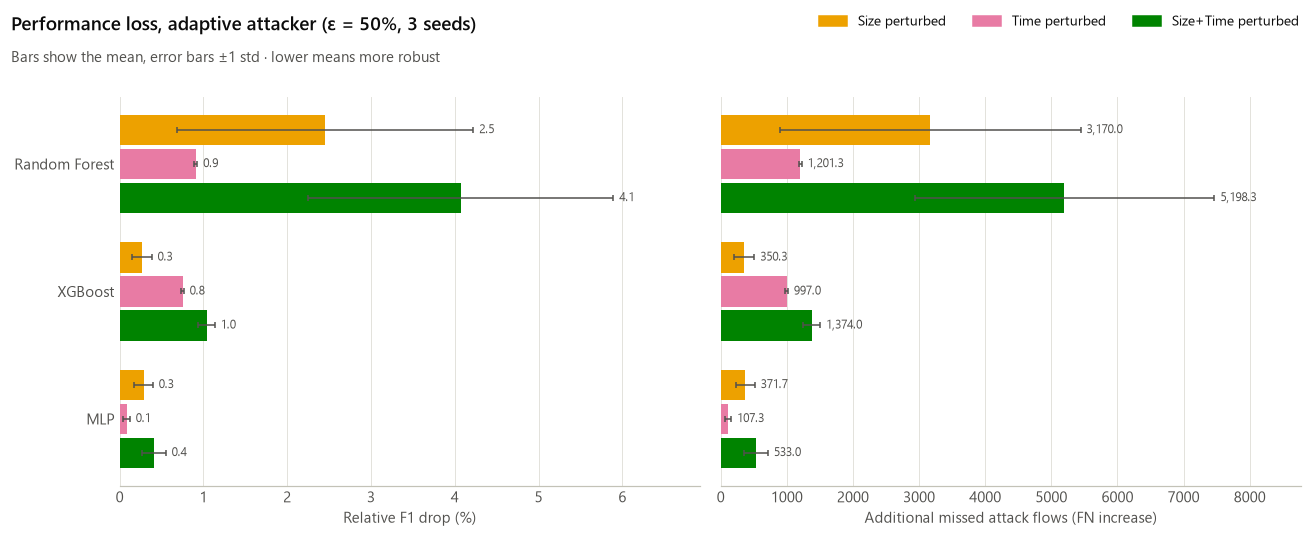

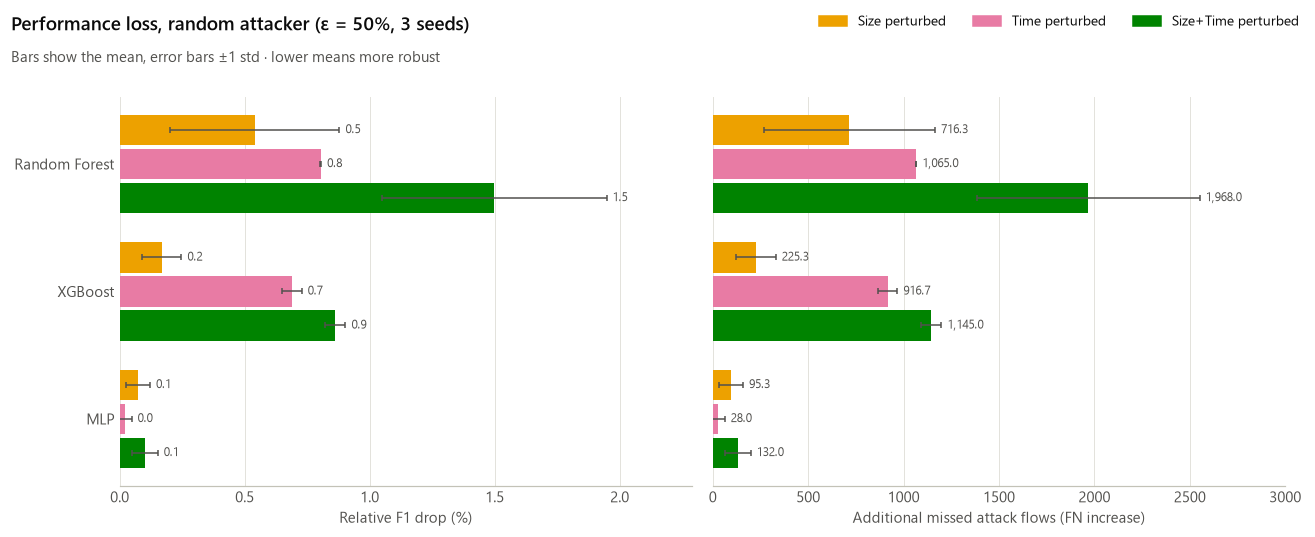

In [21]:
def plot_robustness(attacker, filename):
    sub = at_ref[at_ref["Attacker"] == attacker]
    stats = sub.groupby(["Model", "Group"])[["Relative F1 drop (%)", "FN increase"]].agg(["mean", "std"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    y = np.arange(len(MODEL_NAMES))
    h = 0.8 / len(SCENARIO_GROUPS)
    for ax, metric, xlabel in [(axes[0], "Relative F1 drop (%)", "Relative F1 drop (%)"),
                               (axes[1], "FN increase", "Additional missed attack flows (FN increase)")]:
        for k, group in enumerate(SCENARIO_GROUPS):
            mean = [stats.loc[(n, group), (metric, "mean")] for n in MODEL_NAMES]
            std = [stats.loc[(n, group), (metric, "std")] for n in MODEL_NAMES]
            pos = y - 0.4 + h * (k + 0.5)
            ax.barh(pos, mean, height=h * 0.9, color=SCENARIO_COLORS[group], label=group,
                    xerr=np.nan_to_num(std), error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
            for p, v, s in zip(pos, mean, np.nan_to_num(std)):
                ax.text(max(v, 0) + s, p, f"  {v:,.1f}", va="center", fontsize=8, color=INK_2)
        ax.set_yticks(y, MODEL_NAMES)
        ax.invert_yaxis()
        ax.grid(axis="x"); ax.grid(axis="y", visible=False)
        ax.spines["left"].set_visible(False)
        ax.set_xlabel(xlabel)
        ax.set_xlim(left=0, right=max(ax.get_xlim()[1] * 1.12, 1))
    axes[1].set_yticklabels([])
    fig.tight_layout()
    top_legend(fig, [plt.Rectangle((0, 0), 1, 1, color=SCENARIO_COLORS[g]) for g in SCENARIO_GROUPS],
               [f"{g} perturbed" for g in SCENARIO_GROUPS])
    fig_title(fig, f"Performance loss, {attacker.lower()} attacker (ε = {EPS_REF * 100:.0f}%, {len(SEEDS)} seeds)",
              "Bars show the mean, error bars ±1 std · lower means more robust")
    save_fig(fig, filename)


plot_robustness("Adaptive", "05_robustness_adaptive")
plot_robustness("Random", "06_robustness_random")

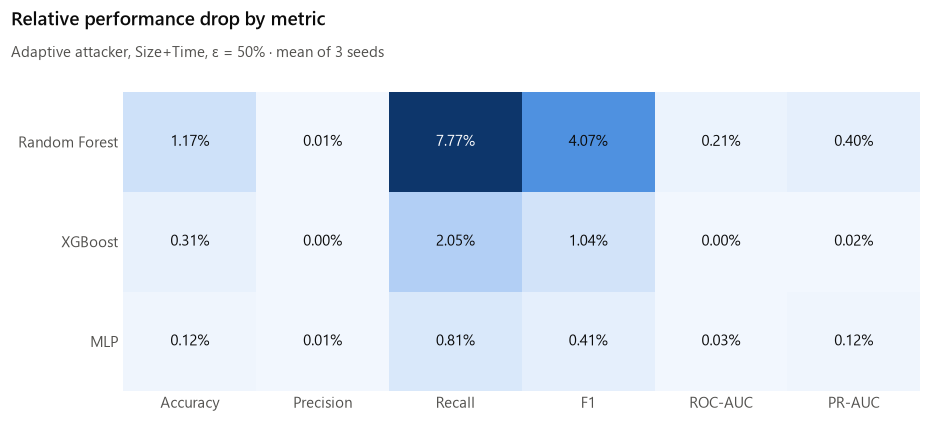

Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest,1.17,0.01,7.77,4.07,0.21,0.40
XGBoost,0.31,0.00,2.05,1.04,0.00,0.02
MLP,0.12,0.01,0.81,0.41,0.03,0.12


In [22]:
# Performans kaybı en çok hangi metrikte? (uyarlamalı, Boyut+Zaman, ε = EPS_REF)
clean_ref = clean.reset_index()
clean_ref = clean_ref[(clean_ref["Attacker"] == "Adaptive") & (clean_ref["Group"] == "Size+Time")]
clean_ref = clean_ref.set_index(["Seed", "Model"])[METRIC_COLS]
main_idx = main.set_index(["Seed", "Model"])
rel_drop = pd.DataFrame({m: -main_idx[f"Δ{m}"] / clean_ref[m].reindex(main_idx.index) * 100 for m in METRIC_COLS})
rel_drop_mean = rel_drop.groupby("Model").mean().loc[MODEL_NAMES]

fig, ax = plt.subplots(figsize=(8.5, 3.2))
vmax = max(rel_drop_mean.to_numpy().max(), 1e-9)
ax.imshow(rel_drop_mean.clip(lower=0).to_numpy(), cmap=BLUE_SEQ, vmin=0, vmax=vmax, aspect="auto")
for i in range(len(MODEL_NAMES)):
    for j in range(len(METRIC_COLS)):
        v = rel_drop_mean.iat[i, j]
        ax.text(j, i, f"{v:.2f}%", ha="center", va="center", fontsize=9.5,
                color="white" if v > 0.55 * vmax else INK)
ax.set_xticks(range(len(METRIC_COLS)), METRIC_COLS)
ax.set_yticks(range(len(MODEL_NAMES)), MODEL_NAMES)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.tight_layout()
fig_title(fig, "Relative performance drop by metric",
          f"Adaptive attacker, Size+Time, ε = {EPS_REF * 100:.0f}% · mean of {len(SEEDS)} seeds")
save_fig(fig, "07_drop_by_metric")

show_table(rel_drop_mean.reset_index(), "Table 11 — Relative drop by metric (%)", "experiment_C_drop_by_metric.csv", precision=2)

In [23]:
# H1 testi: ε ile Recall/F1 arasındaki Spearman sıra korelasyonu (tüm seedlerin noktaları)
h1_rows = []
for (attacker, group, name), d in perturbation_df.groupby(["Attacker", "Group", "Model"], sort=False):
    row = {"Attacker": attacker, "Group": group, "Model": name}
    supported = True
    for metric in ["Recall", "F1"]:
        rho, p = spearmanr(d["Epsilon"], d[metric])
        row[f"ρ ({metric})"], row[f"p ({metric})"] = rho, p
        supported &= bool(rho < 0 and p < 0.05)
    row["H1 supported?"] = "Yes" if supported else "No"
    h1_rows.append(row)
h1_table = pd.DataFrame(h1_rows)
show_table(h1_table, "Table 12 — H1 test: Spearman correlation between ε and Recall/F1 (H1: ρ negative and p below 0.05)",
           "h1_spearman_test.csv")

Attacker,Group,Model,ρ (Recall),p (Recall),ρ (F1),p (F1),H1 supported?
Random,Size,Random Forest,-0.8371,0.0000,-0.8371,0.0000,Yes
Random,Time,Random Forest,-0.9813,0.0000,-0.9813,0.0000,Yes
Random,Size+Time,Random Forest,-0.9875,0.0000,-0.9875,0.0000,Yes
Adaptive,Size,Random Forest,-0.9248,0.0000,-0.9248,0.0000,Yes
Adaptive,Time,Random Forest,-0.9875,0.0000,-0.9875,0.0000,Yes
Adaptive,Size+Time,Random Forest,-0.9875,0.0000,-0.9875,0.0000,Yes
Random,Size,XGBoost,-0.8980,0.0000,-0.8980,0.0000,Yes
Random,Time,XGBoost,-0.8379,0.0000,-0.8783,0.0000,Yes
Random,Size+Time,XGBoost,-0.9750,0.0000,-0.9750,0.0000,Yes
Adaptive,Size,XGBoost,-0.9321,0.0000,-0.9258,0.0000,Yes


## 8. Deney D — Özellik Önemi ve Özellik Grubu Ablation

### 8.1 Özellik önemi

Random Forest (impurity) ve XGBoost (gain) önem değerleri, toplamı 1 olacak şekilde normalize edilir ve seedler üzerinden ortalaması alınır. Çubuk renkleri özelliğin ait olduğu grubu gösterir.

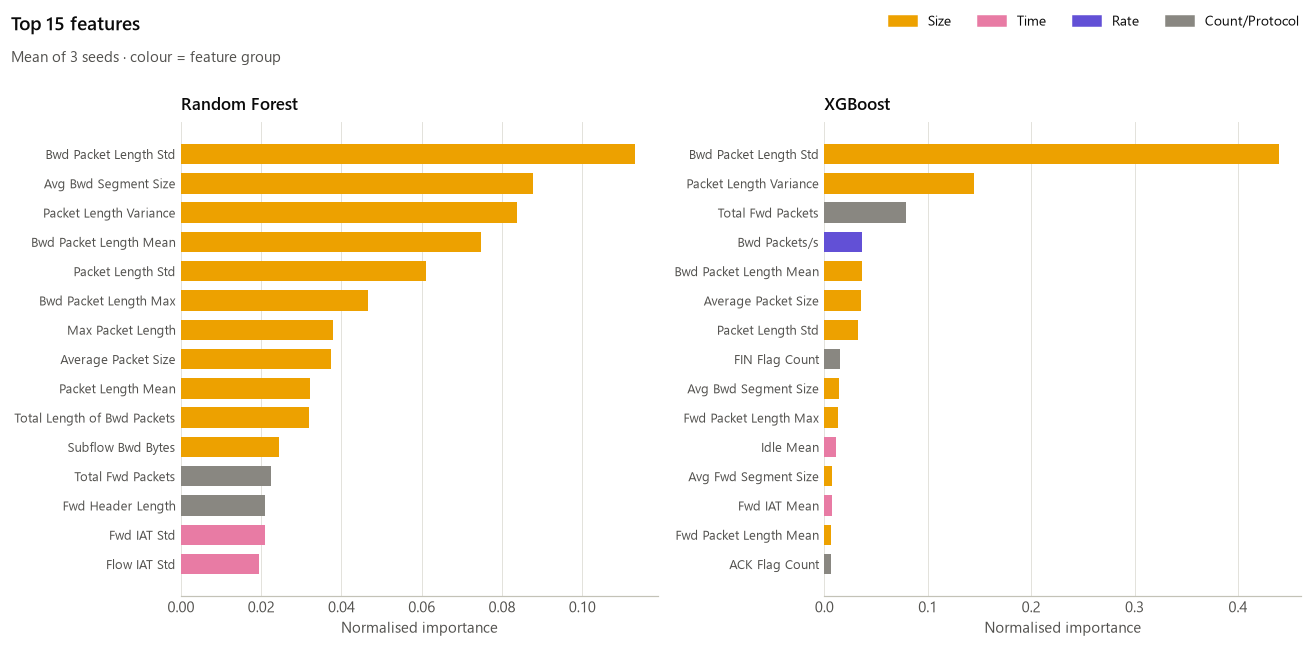

Model,Group,Total importance
Random Forest,Count/Protocol,0.127 ± 0.010
Random Forest,Rate,0.020 ± 0.001
Random Forest,Size,0.689 ± 0.019
Random Forest,Time,0.164 ± 0.009
XGBoost,Count/Protocol,0.140 ± 0.030
XGBoost,Rate,0.039 ± 0.008
XGBoost,Size,0.769 ± 0.050
XGBoost,Time,0.052 ± 0.016


In [24]:
imp_mean = importance_df.groupby(["Model", "Feature"])["Importance"].mean()
tree_models = [n for n in MODEL_NAMES if n in importance_df["Model"].unique()]

fig, axes = plt.subplots(1, len(tree_models), figsize=(12, 5.2))
for ax, name in zip(np.atleast_1d(axes), tree_models):
    top = imp_mean.loc[name].sort_values().tail(15)
    ax.barh(top.index, top.values, color=[GROUP_COLORS[FEATURE_TO_GROUP[f]] for f in top.index], height=0.7)
    ax.set_title(name)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("Normalised importance")
    ax.tick_params(axis="y", labelsize=8.5)
fig.tight_layout()
top_legend(fig, [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()], list(GROUP_COLORS))
fig_title(fig, "Top 15 features", f"Mean of {len(SEEDS)} seeds · colour = feature group")
save_fig(fig, "08_feature_importance")

group_importance = (importance_df.assign(Group=importance_df["Feature"].map(FEATURE_TO_GROUP))
                    .groupby(["Seed", "Model", "Group"])["Importance"].sum().groupby(["Model", "Group"]).agg(["mean", "std"]))
group_imp_table = format_pm(group_importance[["mean"]].rename(columns={"mean": "Total importance"}),
                            group_importance[["std"]].rename(columns={"std": "Total importance"}), digits=3).reset_index()
show_table(group_imp_table, "Table 13 — Total importance per feature group (mean ± std)", "experiment_D_group_importance.csv")

### 8.2 Özellik grubu ablation

Her özellik grubu sırayla veri setinden **çıkarılır** ve modeller kalan özelliklerle **yeniden eğitilir**. Her varyant hem temiz test verisinde hem de uyarlamalı Boyut+Zaman saldırısı altında (ε = `EPS_REF`) değerlendirilir. Pertürbasyon her zaman ham akışın tamamına uygulanır; model yalnızca kendi kullandığı sütunları görür.

Bu sayede iki soru yanıtlanır: (1) Model hangi gruba bağımlı? (2) Bir grubun çıkarılması modeli pertürbasyona karşı daha dayanıklı mı yapıyor?

> Hesaplama süresini makul tutmak için her varyant eğitim kümesinden katmanlı olarak seçilen `ABLATION_TRAIN_SIZE` örnekle eğitilir. Karşılaştırmanın adil olması için "Tüm özellikler" varyantı da aynı alt kümeyle eğitilir.

In [25]:
ABLATION_VARIANTS = {"All features": []}
ABLATION_VARIANTS.update({f"− {group}": cols for group, cols in FEATURE_GROUPS.items()})

ablation_rows = []
start = time.time()
for seed in SEEDS:
    X_tr, X_te, y_tr, y_te = split_data(seed)
    n_sub = min(ABLATION_TRAIN_SIZE, len(X_tr) - 1)
    X_sub, _, y_sub, _ = train_test_split(X_tr, y_tr, train_size=n_sub, stratify=y_tr, random_state=seed)
    bounds = (X_tr.min(), X_tr.max())
    is_attack = (y_te == 1).to_numpy()
    X_att = X_te[is_attack]
    y_eval = np.r_[np.zeros((~is_attack).sum(), dtype=np.int8), np.ones(is_attack.sum(), dtype=np.int8)]
    rng = np.random.default_rng(seed)

    for variant, dropped in ABLATION_VARIANTS.items():
        cols = [c for c in FEATURES if c not in dropped]
        scaler = StandardScaler().fit(X_sub[cols])
        for name in MODEL_NAMES:
            model = make_model(name, seed).fit(scaler.transform(X_sub[cols]).astype(np.float32), y_sub.to_numpy())

            def score_fn(X_raw, model=model, scaler=scaler, cols=cols):
                return model.predict_proba(scaler.transform(X_raw[cols]).astype(np.float32))[:, 1]

            p_clean = score_fn(X_te)
            p_att = attack_probabilities("Adaptive", "Size+Time", EPS_REF, X_att, bounds, score_fn, rng)
            m_clean = compute_metrics(y_te, p_clean)
            m_att = compute_metrics(y_eval, np.r_[p_clean[~is_attack], p_att])
            ablation_rows.append({
                "Seed": seed, "Model": name, "Variant": variant, "Number of features": len(cols),
                "Clean Recall": m_clean["Recall"], "Clean F1": m_clean["F1"],
                "Recall under attack": m_att["Recall"], "F1 under attack": m_att["F1"],
                "FN (clean)": m_clean["FN"], "FN (attack)": m_att["FN"],
            })
    print(f"seed {seed} tamamlandı  ({(time.time() - start) / 60:,.1f} dk)")

ablation_df = pd.DataFrame(ablation_rows)
ablation_df["ΔF1"] = ablation_df["F1 under attack"] - ablation_df["Clean F1"]
ablation_df.to_csv(METRICS_DIR / "raw_experiment_D_ablation_per_seed.csv", index=False, encoding="utf-8-sig")

seed 42 tamamlandı  (4.2 dk)
seed 100 tamamlandı  (9.1 dk)
seed 2024 tamamlandı  (13.7 dk)


Model,Variant,Clean F1,F1 under attack,ΔF1,Clean Recall,Recall under attack
Random Forest,All features,0.9961 ± 0.0002,0.9415 ± 0.0073,-0.0546 ± 0.0074,0.9946 ± 0.0004,0.8916 ± 0.0131
XGBoost,All features,0.9976 ± 0.0001,0.9863 ± 0.0001,-0.0113 ± 0.0001,0.9974 ± 0.0004,0.9751 ± 0.0004
MLP,All features,0.9835 ± 0.0011,0.9788 ± 0.0021,-0.0047 ± 0.0018,0.9806 ± 0.0015,0.9715 ± 0.0023
Random Forest,− Size,0.9958 ± 0.0002,0.9746 ± 0.0030,-0.0213 ± 0.0032,0.9938 ± 0.0005,0.9524 ± 0.0056
XGBoost,− Size,0.9975 ± 0.0001,0.9905 ± 0.0014,-0.0070 ± 0.0013,0.9974 ± 0.0003,0.9834 ± 0.0026
MLP,− Size,0.9701 ± 0.0075,0.9624 ± 0.0043,-0.0077 ± 0.0041,0.9617 ± 0.0167,0.9469 ± 0.0105
Random Forest,− Time,0.9938 ± 0.0001,0.9327 ± 0.0202,-0.0611 ± 0.0202,0.9907 ± 0.0002,0.8770 ± 0.0357
XGBoost,− Time,0.9948 ± 0.0001,0.9510 ± 0.0010,-0.0437 ± 0.0010,0.9918 ± 0.0001,0.9087 ± 0.0019
MLP,− Time,0.9762 ± 0.0028,0.9713 ± 0.0060,-0.0049 ± 0.0041,0.9686 ± 0.0046,0.9592 ± 0.0112
Random Forest,− Rate,0.9962 ± 0.0002,0.9467 ± 0.0024,-0.0495 ± 0.0022,0.9948 ± 0.0004,0.9010 ± 0.0043


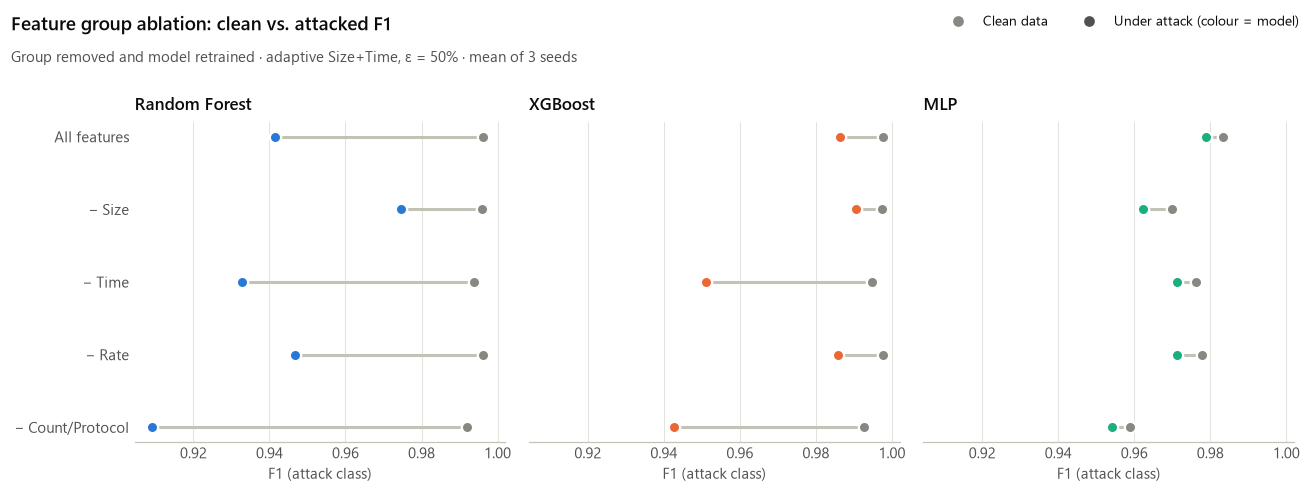

In [26]:
abl_cols = ["Clean F1", "F1 under attack", "ΔF1", "Clean Recall", "Recall under attack"]
g = ablation_df.groupby(["Model", "Variant"], sort=False)[abl_cols]
ablation_table = format_pm(g.mean(), g.std()).reset_index()
show_table(ablation_table,
           f"Table 14 — Experiment D: feature group ablation (adaptive Size+Time attack, ε = {EPS_REF * 100:.0f}%)",
           "experiment_D_ablation.csv")

means = g.mean()
variants = list(ABLATION_VARIANTS)
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(12, 3.8), sharey=True, sharex=True)
for ax, name in zip(axes, MODEL_NAMES):
    d = means.loc[name].reindex(variants)
    yy = np.arange(len(variants))
    ax.hlines(yy, d["F1 under attack"], d["Clean F1"], color=AXIS, linewidth=2, zorder=1)
    ax.scatter(d["Clean F1"], yy, s=55, color=MUTED, edgecolor="white", linewidth=1.5, zorder=2, label="Clean data")
    ax.scatter(d["F1 under attack"], yy, s=55, color=MODEL_COLORS[name], edgecolor="white", linewidth=1.5,
               zorder=3, label="Under attack")
    ax.set_yticks(yy, variants)
    ax.invert_yaxis()
    ax.set_title(name)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("F1 (attack class)")
fig.tight_layout()
top_legend(fig, [Line2D([], [], marker="o", linestyle="", color=MUTED, label="Clean data"),
                 Line2D([], [], marker="o", linestyle="", color=INK_2, label="Under attack (colour = model)")])
fig_title(fig, "Feature group ablation: clean vs. attacked F1",
          f"Group removed and model retrained · adaptive Size+Time, ε = {EPS_REF * 100:.0f}% · mean of {len(SEEDS)} seeds")
save_fig(fig, "09_ablation")

## 9. Sonuçların Özeti

Aşağıdaki hücre, ödevde tartışılması beklenen ilk dört sorunun yanıtlarını üretilen tablolardan otomatik olarak çıkarır. Yorumlar bu çıktılara dayanarak yazılmalıdır.

In [27]:
def pct(v):
    return f"%{v:.2f}"


ref_ad = at_ref[(at_ref["Attacker"] == "Adaptive")]
print(f"Referans: uyarlamalı saldırgan, ε = {EPS_REF * 100:.0f}%, {len(SEEDS)} seed ortalaması\n")

# S1: En az performans kaybı
s1 = main.groupby("Model")[["Relative F1 drop (%)", "Robustness score"]].mean().sort_values("Robustness score", ascending=False)
print("1) En az performans kaybı yaşayan model:", s1.index[0])
for n, r in s1.iterrows():
    print(f"     {n:<14} göreli F1 düşüşü {pct(r['Relative F1 drop (%)'])}, dayanıklılık skoru {r['Robustness score']:.4f}")

# S2: En çok düşen metrik
print("\n2) Performans kaybının en çok görüldüğü metrik:")
for n in MODEL_NAMES:
    row = rel_drop_mean.loc[n]
    print(f"     {n:<14} {row.idxmax()} ({pct(row.max())})   en az: {row.idxmin()} ({pct(row.min())})")

# S3: Özellik grupları
s3 = ref_ad.groupby(["Model", "Group"])["Relative F1 drop (%)"].mean().unstack()[SCENARIO_GROUPS]
print("\n3) Özellik grubuna göre göreli F1 düşüşü:")
for n in MODEL_NAMES:
    r = s3.loc[n]
    print(f"     {n:<14} " + "  ".join(f"{g}: {pct(r[g])}" for g in SCENARIO_GROUPS) + f"   → en etkili: {r.idxmax()}")

# S4: False Negative değişimi
print("\n4) Saldırı sınıfında False Negative sayısı:")
fn_clean = baseline_df.groupby("Model")["FN"].mean()
fn_att = main.groupby("Model")["FN increase"].mean()
n_test_attacks = int(baseline_df[["FN", "TP"]].sum(axis=1).mean())
for n in MODEL_NAMES:
    after = fn_clean[n] + fn_att[n]
    print(f"     {n:<14} temiz {fn_clean[n]:,.0f} → saldırı altında {after:,.0f}  "
          f"(+{fn_att[n]:,.0f}; test kümesindeki {n_test_attacks:,} saldırının %{after / n_test_attacks * 100:.2f}'si kaçırıldı)")

# H1
n_supported = (h1_table["H1 supported?"] == "Yes").sum()
print(f"\nH1: {len(h1_table)} model × saldırgan × grup kombinasyonunun {n_supported} tanesinde "
      "ε arttıkça Recall ve F1 anlamlı biçimde düşüyor (Spearman, p < 0.05).")

Referans: uyarlamalı saldırgan, ε = 50%, 3 seed ortalaması

1) En az performans kaybı yaşayan model: MLP
     MLP            göreli F1 düşüşü %0.41, dayanıklılık skoru 0.9956
     XGBoost        göreli F1 düşüşü %1.04, dayanıklılık skoru 0.9901
     Random Forest  göreli F1 düşüşü %4.07, dayanıklılık skoru 0.9663

2) Performans kaybının en çok görüldüğü metrik:
     Random Forest  Recall (%7.77)   en az: Precision (%0.01)
     XGBoost        Recall (%2.05)   en az: Precision (%0.00)
     MLP            Recall (%0.81)   en az: Precision (%0.01)

3) Özellik grubuna göre göreli F1 düşüşü:
     Random Forest  Size: %2.45  Time: %0.91  Size+Time: %4.07   → en etkili: Size+Time
     XGBoost        Size: %0.26  Time: %0.75  Size+Time: %1.04   → en etkili: Size+Time
     MLP            Size: %0.29  Time: %0.08  Size+Time: %0.41   → en etkili: Size+Time

4) Saldırı sınıfında False Negative sayısı:
     Random Forest  temiz 281 → saldırı altında 5,479  (+5,198; test kümesindeki 67,206 saldırının

### Yorumlar

Aşağıdaki değerler, aksi belirtilmedikçe uyarlamalı saldırgan, Boyut+Zaman pertürbasyonu ve ε = %50 için 3 seed ortalamasıdır.

**Baseline (Deney A).** Üç model de temiz test verisinde çok yüksek başarı göstermektedir: F1 değeri Random Forest için 0.9971, XGBoost için 0.9980, MLP için 0.9870'tir. En az saldırıyı XGBoost kaçırmaktadır (67.206 saldırı akışından 157'si). Sızıntı analizi bu başarının tek bir kısayoldan kaynaklanmadığını göstermektedir: eğitim ve test kümeleri arasında birebir aynı akış yoktur, hiçbir özellik tek başına 0.95'in üzerinde ROC-AUC sağlamamaktadır (en yüksek değer 0.85) ve `Destination Port` eklemek F1 değerini yalnızca 0.9975'ten 0.9983'e çıkarmaktadır.

**1. Hangi model perturbation karşısında en az performans kaybı yaşamıştır?**
Göreli kayıp açısından en dayanıklı model MLP'dir (göreli F1 düşüşü %0.41, dayanıklılık skoru 0.9956). Onu XGBoost (%1.04, 0.9901) ve Random Forest (%4.07, 0.9663) izlemektedir. Ancak saldırı altındaki mutlak F1 değerine bakıldığında XGBoost (0.9876) MLP'nin (0.9829) önündedir. MLP daha az kaybetmektedir çünkü temiz veride zaten daha düşük bir noktadan başlamaktadır. Bu nedenle "en dayanıklı model" sorusunun cevabı, göreli kayıp mı yoksa saldırı altındaki başarı mı ölçüldüğüne bağlıdır. İki ölçütte de en kırılgan model Random Forest'tır: ε = %100'de Recall değeri 0.9958'den 0.8128'e düşmekte, yani her beş saldırıdan biri kaçırılmaktadır. Olası bir açıklama, MLP'nin sürekli bir karar yüzeyine sahip olmasıdır; ağaç modelleri ise keskin eşiklerle karar verdiği için bir eşiğin hemen yanındaki akışlar küçük bir değişiklikle sınıf değiştirebilir.

**2. Performans kaybı en çok hangi metrikte görülmüştür?**
Üç modelde de en büyük kayıp Recall'dadır (RF %7.77, XGBoost %2.05, MLP %0.81). Precision neredeyse hiç değişmemektedir (%0.01 ve altı). Bu beklenen bir sonuçtur, çünkü tehdit modelinde yalnızca saldırı akışları değiştirilmiş, normal trafiğe dokunulmamıştır. Dolayısıyla yanlış alarm (FP) sayısı artmamış, yalnızca kaçırılan saldırı (FN) sayısı artmıştır. Accuracy ise sınıf dengesizliği nedeniyle (verinin %85'i normal trafik) çok az düşmektedir (RF %1.17); bu durum accuracy'nin bu problemde tek başına yanıltıcı olduğunu göstermektedir. ROC-AUC ve PR-AUC'deki düşüş de küçüktür: model olasılıkları sıralamada hâlâ büyük ölçüde doğrudur, ancak pertürbe edilen akışlar karar eşiğinin altına inmektedir.

**3. Bazı özellik gruplarındaki değişiklikler diğerlerinden daha mı etkilidir?**
Evet. Boyut ve zamanın birlikte değiştirilmesi her modelde en etkili senaryodur. Tek grup karşılaştırıldığında Random Forest boyut değişikliklerine (%2.45), XGBoost ise zaman değişikliklerine (%0.75) daha duyarlıdır. Bu sonuç özellik önemiyle tutarlıdır: boyut özellikleri RF'de toplam önemin %69'unu, XGBoost'ta %77'sini oluşturmaktadır.

Zaman pertürbasyonunda dikkat çeken bir durum vardır: Random Forest ve XGBoost'un Recall değeri yalnızca %5'lik bir gecikmeyle ani bir düşüş göstermekte, daha büyük ε değerlerinde ise neredeyse sabit kalmaktadır. Ek analiz (Tablo 8e), bu gecikmeyle kaçan 883 akışın büyük çoğunluğunun **DoS Slowhttptest** (530 akış, test kümesindekilerin %52'si) ve **DoS slowloris** (328 akış, %31) saldırılarına ait olduğunu göstermektedir. Kaçan akışların medyan süresi 63.1 saniyedir. Bu "yavaş DoS" araçları sabit zamanlayıcılarla çalıştığından model bu saldırıları davranışlarından çok **sabit bir süre imzasından** tanımayı öğrenmiştir ve küçük bir gecikme bu imzayı bozmaya yetmektedir. Bu bulgu, modelin başarısının bir kısmının veri setine özgü ipuçlarına dayanabileceğini göstermektedir.

Ablation sonuçları (Tablo 14) dayanıklılığın kaynağını da göstermektedir:
- Boyut grubu çıkarıldığında Random Forest daha dayanıklı hâle gelmektedir (ΔF1 −0.055'ten −0.021'e). Saldırganın manipüle ettiği gruba bağımlılığın azalması kaybı azaltmaktadır.
- Saldırganın değiştiremediği **Sayaç/Protokol** grubu (paket sayıları, TCP bayrakları, pencere boyutu) çıkarıldığında ise kayıp en çok artmaktadır (RF'de ΔF1 −0.083, XGBoost'ta −0.050). Bu özellikler modelin pertürbasyona karşı "çapası" gibi çalışmaktadır.
- Zaman grubu çıkarıldığında XGBoost'un kaybı artmaktadır (−0.011'den −0.044'e), çünkü model bu durumda saldırganın değiştirebildiği boyut özelliklerine daha fazla dayanmaktadır.

Buradan çıkan pratik öneri şudur: saldırganın değiştirmesi zor olan özelliklere dayanan modeller adversarial değişikliklere karşı daha dayanıklıdır.

**4. Saldırı tespitindeki False Negative sayısı nasıl değişmiştir?**
Kaçırılan saldırı sayısı Random Forest'ta 281'den 5.479'a (test kümesindeki saldırıların %8.15'i), XGBoost'ta 157'den 1.531'e (%2.28), MLP'de 1.051'den 1.584'e (%2.36) yükselmiştir. ε = %100'de Random Forest için bu sayı 12.581'e ulaşmaktadır (Tablo 8c). ε = %50'de uyarlamalı saldırgan bütün model ve grup kombinasyonlarında rastgele saldırgandan daha fazla FN üretmektedir: modelin skorunu sorgulayabilen bir saldırgan, rastgele değişikliklere göre çok daha etkilidir.

**Hipotez H1.** 18 model × saldırgan × grup kombinasyonunun 17'sinde ε ile Recall ve F1 arasında negatif ve istatistiksel olarak anlamlı bir Spearman korelasyonu bulunmuştur (p < 0.05). Tek istisna, MLP'nin rastgele zaman pertürbasyonudur: bu senaryoda Recall anlamlı biçimde düşmekte, F1'deki değişim ise anlamlı değildir. Bu nedenle **H1 desteklenmektedir**: pertürbasyon seviyesi arttıkça saldırı sınıfına ilişkin Recall ve F1 düşmektedir. Ancak düşüşün büyüklüğü modele göre çok farklıdır. Kısıtlar altında bu düşüş sınırlı kalmaktadır: en kötü durumda bile Recall 0.81'in altına inmemektedir. Bu sonuç, ağ kısıtlarını korumayan (ör. normal trafiği de değiştiren veya negatif değerler üreten) pertürbasyonların modellerin kırılganlığını olduğundan çok daha büyük gösterebileceğine işaret etmektedir.

**Veri seti ile ilgili not.** Temizlik sırasında PortScan kayıtlarının büyük kısmı silinmiştir: tam satır tekrarları atıldıktan sonra bile yaklaşık 90 bin olan PortScan kaydı, etiket çakışması ve özellik bazlı tekilleştirme sonrasında 1.850'ye inmiştir. Bu kayıtların çoğu ya birbirinin birebir kopyasıdır ya da aynı özelliklerle "BENIGN" olarak da etiketlenmiştir. Bu, CIC-IDS2017'nin bilinen etiketleme sorunlarından biridir ve PortScan'e ilişkin sonuçların temkinli yorumlanması gerektiğini göstermektedir.

## 10. Tartışma ve Sınırlılıklar

**Deneysel sonuçlar gerçek ağ ortamına ne ölçüde genellenebilir? (Soru 5)**

Bu çalışmadaki saldırılar **özellik uzayında** yapılmıştır: akışı oluşturan paketler yeniden üretilmemiş, CICFlowMeter'ın çıkardığı özellikler doğrudan değiştirilmiştir. Pertürbasyonlar ağ trafiğinin temel kısıtlarını koruyacak biçimde tasarlanmıştır: yalnızca saldırganın kendi paketleri değişir, değerler azaltılmaz, paket sayısı sabit kalır, türetilmiş özellikler yeniden hesaplanır ve değerler eğitim aralığında tutulur. Buna rağmen aşağıdaki nedenlerle sonuçlar, **gerçek bir saldırganın sistemi aşabileceğinin kesin kanıtı olarak yorumlanmamalıdır**:

- **Yaklaşıklıklar.** Çift yönlü dağılım özellikleri (`Packet Length Std/Variance`, `Min Packet Length`) paket düzeyindeki veri olmadan yeniden hesaplanamadığı için değiştirilmemiştir. Zaman pertürbasyonu akışın tamamen ve orantılı olarak yavaşlaması varsayımına dayanır; gerçekte gecikme yalnızca ileri yön paketlerine eklenir ve sunucu yanıtlarının zamanlaması farklı etkilenebilir.
- **İşlevsellik.** Padding ve gecikmenin saldırının amacını (ör. DoS'un etkisini, brute-force hızını) ne kadar azalttığı ölçülmemiştir. Bir akışın tespitten kaçması, saldırının hâlâ başarılı olduğu anlamına gelmez.
- **Saldırgan bilgisi.** Uyarlamalı saldırgan modelin skorunu sınırsız sorgulayabildiği varsayımıyla çalışır. Gerçek bir IDS yalnızca alarm/alarm yok bilgisi verebilir ve çok sayıda sorgu kendi başına şüpheli olabilir.
- **Veri seti yanlılığı.** CIC-IDS2017 kontrollü bir laboratuvar ortamında üretilmiştir; saldırılar belirli günlere, saatlere ve portlara yoğunlaşır. Rastgele bölme, aynı saldırı oturumundan gelen çok benzer akışları hem eğitim hem test kümesine yerleştirir ve baseline sonuçlarını iyimser gösterir (bkz. Bölüm 5).
- **Tek veri seti.** Sonuçların farklı bir ağ ortamında korunup korunmadığı, CSE-CIC-IDS2018 üzerinde tekrarlanan deneyle ayrıca incelenecektir.